# Kiểm định giả thuyết BTCUSDT và ETHUSDT (nến 1 giờ, Binance, từ khi mở sàn năm 2017)

Notebook này là phần kiểm định đi kèm `crypto_1h_eda.ipynb`. Notebook EDA mô tả và tìm ra các phát hiện; notebook này kiểm tra từng phát hiện có đứng vững về mặt thống kê hay không, và gắn mỗi phát hiện với một mức bằng chứng.

Dữ liệu đầu vào là `crypto_1h_clean.csv`, kết quả của bước làm sạch bằng SQL (`sql/03_clean.sql`, xuất ra csv bằng `python/export_clean_csv.py`), và dùng cùng phạm vi, cùng quy ước với notebook EDA: toàn bộ lịch sử từ 17/08/2017, bỏ nến cuối chưa đóng, mọi phân tích theo giờ, thứ và ngày dùng giờ Việt Nam (UTC+7), bỏ ngày đầu và ngày cuối vì chưa đủ 24 giờ. Notebook chạy độc lập, không cần chạy notebook EDA trước.

Mỗi giả thuyết H1 đến H12 có một biểu đồ minh chứng riêng ở phần 4, đặt cạnh ước lượng, khoảng tin cậy và ngưỡng thực tế, để quan sát trực tiếp dữ liệu đằng sau từng con số ở bảng kết quả.

In [1]:
import os, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # thư mục gốc của repo
FIG = ROOT / "reports" / "figures"
os.makedirs(FIG, exist_ok=True)

CLEAN = ROOT / "data" / "crypto_1h_clean.csv"
START = pd.Timestamp("2017-08-17", tz="UTC")     # ngày sàn bắt đầu có dữ liệu: toàn bộ lịch sử được đưa vào phân tích
THIN = pd.Timestamp("2018-01-01", tz="UTC")      # hết giai đoạn thị trường mỏng (is_thin_period), dùng để tô nền và so sánh
SPLIT = pd.Timestamp("2022-01-01", tz="Asia/Ho_Chi_Minh")   # mốc chia hai nửa để kiểm tra độ ổn định
TZ = "Asia/Ho_Chi_Minh"
SYMS = ["BTCUSDT", "ETHUSDT"]
NAME = {"BTCUSDT": "BTC", "ETHUSDT": "ETH"}
COL = {"BTCUSDT": "#2a78d6", "ETHUSDT": "#eb6834"}   # màu cố định theo mã, không đổi giữa các biểu đồ
BG, INK, INK2, GRID, GREY = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0", "#b9b8b1"
DOW = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "axes.edgecolor": GREY, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
    "grid.linewidth": 0.7, "axes.axisbelow": True, "font.size": 9.5, "legend.frameon": False,
    "figure.dpi": 100,
})

def vn(x, d=1, pct=False, sign=False):
    # định dạng số kiểu Việt Nam: dấu chấm ngăn nghìn, dấu phẩy thập phân
    v = x * 100 if pct else x
    if round(v, d) == 0:
        v = 0.0
    s = f"{abs(v):,.{d}f}".replace(",", "§").replace(".", ",").replace("§", ".")
    s = ("-" if v < 0 else "+" if sign else "") + s
    return s + ("%" if pct else "")

def dmy(ts): return pd.Timestamp(ts).strftime("%d/%m/%Y")
def times(m): return f"gấp {vn(m, 1)} lần" if m >= 1 else f"còn {vn(m, 0, pct=True)} so với ban đầu"
def ttl(ax, s): ax.set_title(textwrap.fill(s, 78), loc="left", fontsize=11, fontweight="bold", color=INK, pad=10)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150, facecolor=BG)
    plt.show()
fmt_int = mt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
fmt_pct0 = mt.FuncFormatter(lambda v, _: vn(v, 0, pct=True))

In [2]:
raw = pd.read_csv(CLEAN, encoding="utf-8-sig", parse_dates=["open_time"])
df = raw[(raw["open_time"] >= START) & (~raw["is_incomplete"])].copy()
df["t"] = df["open_time"].dt.tz_convert(TZ)
df["hour"] = df["t"].dt.hour
df["day"] = df["t"].dt.tz_localize(None).dt.floor("D")

# bảng theo ngày: bỏ ngày đầu và ngày cuối vì chưa đủ giờ
daily = (df.groupby(["symbol", "day"])
           .agg(close=("close", "last"), qv=("quote_volume", "sum"), tbq=("taker_buy_quote", "sum"))
           .reset_index())
d0, d1 = daily["day"].min(), daily["day"].max()
daily = daily[(daily["day"] > d0) & (daily["day"] < d1)].copy()
daily["ret"] = daily.groupby("symbol")["close"].transform(lambda s: np.log(s).diff())
dr = daily.pivot(index="day", columns="symbol", values="ret")[SYMS].dropna()

# return giờ: chuỗi đầy đủ có NaN ở giờ thiếu, và bảng dài không có NaN
ret_h = df.pivot(index="open_time", columns="symbol", values="ret_1h")[SYMS]
h = df.dropna(subset=["ret_1h"]).copy()
h["ar"] = h["ret_1h"].abs()
LAGS = np.arange(1, 169)
acf_r = pd.DataFrame({s: [ret_h[s].autocorr(k) for k in LAGS] for s in SYMS}, index=LAGS)
acf_a = pd.DataFrame({s: [ret_h[s].abs().autocorr(k) for k in LAGS] for s in SYMS}, index=LAGS)

# dòng lệnh chủ động mua và khối lượng tương đối
fl = df[df["quote_volume"] > 0].copy()
fl["tbr"] = fl["taker_buy_quote"] / fl["quote_volume"]
fl = fl.sort_values(["symbol", "open_time"])
fl["next_ret"] = fl.groupby("symbol")["ret_1h"].shift(-1)
dv = daily.copy()
dv["rel_vol"] = dv["qv"] / dv.groupby("symbol")["qv"].transform(lambda s: s.rolling(30).median().shift(1))
dv["abs_ret"] = dv["ret"].abs()
dv = dv.dropna(subset=["rel_vol", "abs_ret"])

# return trung bình từng giờ trong ngày (t-test, Bonferroni 24 giờ cho từng mã)
res = []
for s in SYMS:
    g = h[h["symbol"] == s].groupby("hour")["ret_1h"]
    m, se = g.mean(), g.sem()
    p = g.apply(lambda v: stats.ttest_1samp(v, 0).pvalue)
    res.append(pd.DataFrame({"s": s, "mean_bp": m * 1e4, "ci_bp": 1.96 * se * 1e4, "p": p, "p_bonf": (p * 24).clip(upper=1)}))
res = pd.concat(res)
nbon = res.groupby("s")["p_bonf"].apply(lambda v: int((v < 0.05).sum()))

print(f"Phạm vi: {dmy(df['t'].min())} đến {dmy(df['t'].max())} (giờ Việt Nam); {len(h):,} giờ có return, {len(dr)} ngày đầy đủ.".replace(",", "."))

Phạm vi: 17/08/2017 đến 10/11/2026 (giờ Việt Nam); 161.550 giờ có return. 3370 ngày đầy đủ.


## 1. Khung kiểm định và quy tắc xếp mức bằng chứng

Notebook EDA chủ yếu mô tả. Notebook này biến các phát hiện chính thành giả thuyết kiểm định được, khai báo ngưỡng trước khi xem kết quả, rồi gắn mỗi phát hiện với một mức bằng chứng. Quy trình gồm năm bước.

1. **Khai báo trước.** Mỗi giả thuyết có giả thuyết không (H0), thống kê dùng để kiểm, và một ngưỡng độ lớn có ý nghĩa thực tế. Giả thuyết và ngưỡng được cố định trong code trước khi chạy kiểm định, nhưng được đặt sau khi đã xem kết quả mô tả ở notebook EDA. Vì vậy đây là kiểm định xác nhận có điều kiện, không phải kiểm định tiền đăng ký thực sự, và p-value cần đọc thận trọng hơn.
2. **Kiểm định chịu được phụ thuộc theo thời gian.** Return giờ không độc lập: độ lớn biến động tự tương quan mạnh, nên kiểm định thông thường (t-test, Mann–Whitney, p-value của Spearman) coi mỗi giờ là một quan sát độc lập và cho p-value quá nhỏ. Notebook này dùng block bootstrap (resample từng khối ngày liên tiếp để giữ nguyên tự tương quan, khối 168 giờ với dữ liệu giờ, 14 đến 30 ngày với dữ liệu ngày), sai số chuẩn Newey–West cho trung bình, và kiểm định Friedman cho mùa vụ theo giờ (mỗi ngày là một khối).
3. **Hiệu chỉnh nhiều phép thử.** Toàn bộ các phép thử của notebook này được coi là một họ và hiệu chỉnh bằng phương pháp Holm, kiểm soát xác suất có ít nhất một kết luận sai ở mức 5%.
4. **Độ lớn hiệu ứng với khoảng tin cậy, không chỉ p-value.** Mẫu hàng chục nghìn giờ làm hiệu ứng rất nhỏ cũng có p nhỏ, nên một phát hiện chỉ được coi là có ý nghĩa thực tế khi độ lớn vượt ngưỡng đã khai báo.
5. **Độ ổn định.** Hiệu ứng phải còn cùng hướng và còn có ý nghĩa khi chia đôi mẫu (trước và từ 2022) và khi bỏ năm 2017.

Quy tắc xếp mức bằng chứng, áp dụng cho từng phép thử theo thứ tự:

- **Không đáng kể**: không có ý nghĩa sau Holm, và khoảng tin cậy nằm hoàn toàn dưới ngưỡng thực tế, tức là nếu có hiệu ứng thì nhỏ.
- **Chưa kết luận**: không có ý nghĩa sau Holm, nhưng khoảng tin cậy còn rộng đến mức chưa loại được hiệu ứng vượt ngưỡng. Không bác bỏ H0 không có nghĩa là đã chứng minh H0.
- **Ngược chiều**: có ý nghĩa nhưng ngược hướng với giả thuyết.
- **Yếu**: có ý nghĩa nhưng độ lớn chưa tới ngưỡng thực tế.
- **Vừa**: có ý nghĩa và vượt ngưỡng, nhưng không ổn định hoặc chưa kiểm tra được độ ổn định.
- **Mạnh**: có ý nghĩa, vượt ngưỡng, và ổn định ở cả hai nửa lẫn khi bỏ 2017.

## 2. Giả thuyết đã khai báo và cỡ mẫu hiệu dụng

In [3]:
RNG = np.random.default_rng(2026)          # cố định hạt giống để kết quả lặp lại được
B_MAIN, B_DAY, B_SUB = 2000, 10000, 400    # số lần resample: dữ liệu giờ, dữ liệu ngày (rẻ hơn nên lấy nhiều hơn), và mẫu con
THIN_N, SPLIT_N = THIN.tz_localize(None), SPLIT.tz_localize(None)
TAIL0 = 2 * stats.norm.sf(3)               # tỉ lệ ngoài ±3σ của phân phối chuẩn (0,27%)

def block_ix(n, L):
    L = int(max(1, min(L, n)))
    st = RNG.integers(0, n - L + 1, -(-n // L))
    return (st[:, None] + np.arange(L)).ravel()[:n]

def boot(stat, arrs, L, B):
    # block bootstrap: các mảng được resample cùng chỉ số để giữ quan hệ giữa chúng
    n = len(arrs[0])
    return np.array([stat(*[a[ix] for a in arrs]) for ix in (block_ix(n, L) for _ in range(B))])

def boot2(stat, A, Bs, La, Lb, B):
    # hai mẫu độc lập (hai giai đoạn), mỗi mẫu resample theo khối riêng
    out = []
    for _ in range(B):
        ia, ib = block_ix(len(A[0]), La), block_ix(len(Bs[0]), Lb)
        out.append(stat([a[ia] for a in A], [b[ib] for b in Bs]))
    return np.array(out)

def boot_p(ts, null):
    B = len(ts)
    return min(1.0, 2 * min(((ts <= null).sum() + 1) / (B + 1), ((ts >= null).sum() + 1) / (B + 1)))
ci95 = lambda ts: tuple(np.percentile(ts, [2.5, 97.5]))

def holm(p):
    p = np.asarray(p, float); adj = np.empty(len(p)); run = 0.0
    for r, i in enumerate(np.argsort(p)):
        run = max(run, (len(p) - r) * p[i]); adj[i] = min(1.0, run)
    return adj

def nw_mean(x, lags=10):
    # trung bình với sai số chuẩn Newey–West (nhân Bartlett), chịu được tự tương quan và phương sai thay đổi
    n = len(x); m = x.mean(); e = x - m
    v = (e * e).sum() / n
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * (e[k:] * e[:-k]).sum() / n
    se = np.sqrt(v / n)
    return m, se, 2 * stats.norm.sf(abs(m / se)), (m - 1.96 * se, m + 1.96 * se)

# thống kê
def s_tail(x):
    x = x[~np.isnan(x)]
    return (np.abs(x - x.mean()) > 3 * x.std()).mean() / TAIL0
def s_ac1(x):
    a, b = x[1:], x[:-1]; ok = ~(np.isnan(a) | np.isnan(b))     # bỏ các cặp có giờ thiếu, giống notebook EDA
    return np.corrcoef(a[ok], b[ok])[0, 1]
s_ac1a = lambda x: s_ac1(np.abs(x))
s_cor = lambda u, v: np.corrcoef(u, v)[0, 1]
s_sd = lambda A, Bs: Bs[0].std() / A[0].std()
s_dcor = lambda A, Bs: s_cor(*Bs) - s_cor(*A)
s_wk = lambda ar, we: np.median(ar[we == 1]) / np.median(ar[we == 0])
s_prof = lambda M: M.mean(0).max() / M.mean(0).min()
rk = stats.rankdata

# dữ liệu và cửa sổ thời gian
HH = h
FL = fl.dropna(subset=["tbr", "ret_1h", "next_ret"])
DD = daily.dropna(subset=["ret"]).assign(ar=lambda d: d["ret"].abs(), we=lambda d: (d["day"].dt.dayofweek >= 5).astype(float))
DV = dv
DRD = dr.reset_index()
def wh(d, w):
    if w == "before": return d[d["t"] < SPLIT]
    if w == "after": return d[d["t"] >= SPLIT]
    if w == "ex17": return d[d["open_time"] >= THIN]
    return d
def wd(d, w):
    if w == "before": return d[d["day"] < SPLIT_N]
    if w == "after": return d[d["day"] >= SPLIT_N]
    if w == "ex17": return d[d["day"] >= THIN_N]
    return d

def get_ret(s, w):
    x = ret_h[s]; ix = x.index          # chuỗi giờ đầy đủ có NaN ở giờ thiếu, cùng cách tính với notebook EDA
    if w == "before": x = x[ix.tz_convert(TZ) < SPLIT]
    elif w == "after": x = x[ix.tz_convert(TZ) >= SPLIT]
    elif w == "ex17": x = x[ix >= THIN]
    return [x.to_numpy()]
def get_wk(s, w):
    g = wd(DD[DD["symbol"] == s], w); return [g["ar"].to_numpy(), g["we"].to_numpy()]
def get_pair(s, w):
    g = wd(DRD, w); return [g["BTCUSDT"].to_numpy(), g["ETHUSDT"].to_numpy()]
def get_vol(s, w):
    g = wd(DV[DV["symbol"] == s], w); return [rk(g["rel_vol"]), rk(g["abs_ret"])]
def get_tbr(s, w):
    g = wh(FL[FL["symbol"] == s], w); return [rk(g["tbr"]), rk(g["next_ret"])]
def get_sd(s, w):
    g = DD[DD["symbol"] == s]; lo = THIN_N if w == "ex17" else g["day"].min()
    return [g.loc[(g["day"] >= lo) & (g["day"] < SPLIT_N), "ret"].to_numpy()], [g.loc[g["day"] >= SPLIT_N, "ret"].to_numpy()]
def get_dcor(s, w):
    a, b = DRD[DRD["day"] < THIN_N], DRD[DRD["day"] >= THIN_N]
    return [a["BTCUSDT"].to_numpy(), a["ETHUSDT"].to_numpy()], [b["BTCUSDT"].to_numpy(), b["ETHUSDT"].to_numpy()]

f_x = lambda v: "×" + vn(v, 2)
f_r = lambda v: vn(v, 3, sign=True)
f_b = lambda v: vn(v, 1, sign=True) + " bp"
ALL3 = ("before", "after", "ex17")
SPEC = [
 dict(id="H1", name="Return giờ có đuôi dày hơn phân phối chuẩn", kind="boot", syms=SYMS, get=get_ret, stat=s_tail, L=168, null=1.0, thr=2.0, mode="dir", wins=ALL3, fmt=lambda v: "×" + vn(v, 1),
      h0="Tỉ lệ giờ ngoài ±3σ bằng mức của phân phối chuẩn (0,27%)", test="Block bootstrap; thống kê = tỉ lệ ngoài ±3σ chia 0,27%", thr_txt="≥ ×2 so với chuẩn"),
 dict(id="H2", name="Return giờ tự tương quan (lag 1)", kind="boot", syms=SYMS, get=get_ret, stat=s_ac1, L=168, null=0.0, thr=0.10, mode="two", wins=ALL3, fmt=f_r,
      h0="ACF lag 1 của return bằng 0", test="Block bootstrap; thống kê = ACF lag 1", thr_txt="|ρ| ≥ 0,10"),
 dict(id="H3", name="Biến động gom cụm (ACF của |return|, lag 1)", kind="boot", syms=SYMS, get=get_ret, stat=s_ac1a, L=168, null=0.0, thr=0.10, mode="dir", wins=ALL3, fmt=f_r,
      h0="ACF lag 1 của |return| bằng 0", test="Block bootstrap; thống kê = ACF lag 1 của |return|", thr_txt="ρ ≥ 0,10"),
 dict(id="H4", B=B_DAY, name="Biến động ngày từ 2022 thấp hơn trước 2022", kind="boot2", syms=SYMS, get=get_sd, stat=s_sd, L=(30, 30), null=1.0, thr=0.80, mode="dir", wins=("ex17",), fmt=f_x,
      h0="σ ngày từ 2022 / σ ngày trước 2022 = 1", test="Block bootstrap hai mẫu; thống kê = tỉ số độ lệch chuẩn", thr_txt="≤ ×0,80 (giảm ≥ 20%)"),
 dict(id="H5", name="Biên độ biến động khác nhau giữa 24 giờ trong ngày", kind="h5", syms=SYMS, null=1.0, thr=1.30, mode="dir", fmt=lambda v: "×" + vn(v, 2),
      h0="|return| có cùng mức ở cả 24 giờ", test="Friedman (mỗi ngày là một khối); KTC bootstrap theo tuần cho tỉ số giờ mạnh/giờ yếu", thr_txt="≥ ×1,30 (giờ mạnh nhất / yếu nhất)"),
 dict(id="H6", B=B_DAY, name="Cuối tuần biến động thấp hơn ngày thường", kind="boot", syms=SYMS, get=get_wk, stat=s_wk, L=14, null=1.0, thr=0.85, mode="dir", wins=ALL3, fmt=f_x,
      h0="|return ngày| trung vị cuối tuần = ngày thường", test="Block bootstrap; thống kê = tỉ số trung vị", thr_txt="≤ ×0,85 (thấp hơn ≥ 15%)"),
 dict(id="H7", name="Return log trung bình mỗi ngày khác 0", kind="hac", syms=SYMS, null=0.0, thr=5.0, mode="two", fmt=f_b,
      h0="Return log trung bình ngày bằng 0", test="Trung bình với sai số chuẩn Newey–West (10 độ trễ)", thr_txt="|trung bình| ≥ 5 bp/ngày (≈ 20%/năm)"),
 dict(id="H8", B=B_DAY, name="BTC và ETH đồng pha mạnh (tương quan ngày)", kind="boot", syms=[None], get=get_pair, stat=s_cor, L=30, null=0.5, thr=0.70, mode="dir", wins=ALL3, fmt=lambda v: "ρ = " + vn(v, 2), fc=lambda v: vn(v, 2),
      h0="Tương quan Pearson của return ngày ≤ 0,5", test="Block bootstrap; thống kê = Pearson của return ngày", thr_txt="ρ ≥ 0,70"),
 dict(id="H9", B=B_DAY, name="Tương quan BTC–ETH năm 2017 thấp hơn các năm sau", kind="boot2", syms=[None], get=get_dcor, stat=s_dcor, L=(14, 30), null=0.0, thr=0.10, mode="dir", wins=(), fmt=lambda v: "Δρ = " + vn(v, 2, sign=True), fc=lambda v: vn(v, 2, sign=True),
      h0="Tương quan từ 2018 trừ tương quan 2017 = 0", test="Block bootstrap hai mẫu; thống kê = chênh lệch tương quan", thr_txt="Δρ ≥ 0,10"),
 dict(id="H10", B=B_DAY, name="Khối lượng tương đối đi cùng độ lớn return ngày", kind="boot", syms=SYMS, get=get_vol, stat=s_cor, L=30, null=0.0, thr=0.30, mode="dir", wins=ALL3, fmt=lambda v: "ρ = " + vn(v, 2), fc=lambda v: vn(v, 2),
      h0="Spearman (khối lượng tương đối, |return ngày|) = 0", test="Block bootstrap; thống kê = Spearman", thr_txt="ρ ≥ 0,30"),
 dict(id="H11", name="Tỉ lệ mua chủ động dự báo return giờ kế tiếp", kind="boot", syms=SYMS, get=get_tbr, stat=s_cor, L=168, null=0.0, thr=0.10, mode="two", wins=ALL3, fmt=f_r,
      h0="Spearman (tỉ lệ mua chủ động giờ t, return giờ t+1) = 0", test="Block bootstrap; thống kê = Spearman", thr_txt="|ρ| ≥ 0,10"),
 dict(id="H12", name="Có giờ nào trong ngày có return trung bình khác 0", kind="h12", syms=SYMS, null=0.0, thr=10.0, mode="two", fmt=f_b,
      h0="Return trung bình của mọi giờ trong ngày bằng 0", test="t-test từng giờ, Bonferroni 24 giờ; lấy giờ lệch nhất", thr_txt="|trung bình| ≥ 10 bp/giờ (≈ phí một chiều)"),
]
lab = lambda s: NAME.get(s, "BTC–ETH")
display(pd.DataFrame([{"Mã": x["id"], "Giả thuyết": x["name"], "H0": x["h0"], "Kiểm định": x["test"], "Ngưỡng thực tế": x["thr_txt"]} for x in SPEC]).set_index("Mã"))

# cỡ mẫu hiệu dụng: vì sao không dùng kiểm định giả định độc lập
fi = lambda v: f"{v:,.0f}".replace(",", ".")
ne = []
for s in SYMS:
    n = int(ret_h[s].count())
    n_r, n_a = min(n, n / max(1 + 2 * acf_r[s].sum(), 1)), min(n, n / max(1 + 2 * acf_a[s].sum(), 1))
    ne.append({"Mã": NAME[s], "số giờ": fi(n), "cỡ mẫu hiệu dụng của return": fi(n_r), "cỡ mẫu hiệu dụng của |return|": fi(n_a)})
    ne_a = n_a
display(pd.DataFrame(ne).set_index("Mã"))
print(f"Cỡ mẫu hiệu dụng = n / (1 + 2·Σ ACF) với 168 độ trễ. Với |return|, {fi(n)} giờ chỉ tương đương cỡ {fi(ne_a)} quan sát độc lập, "
      "nên các kiểm định giả định độc lập sẽ cho p-value nhỏ hơn thực tế; block bootstrap tránh được vấn đề này. "
      "Cỡ mẫu hiệu dụng ở đây là cận trên vì chỉ cộng 168 độ trễ.")

,Giả thuyết,H0,Kiểm định,Ngưỡng thực tế
Mã,,,,
H1,Return giờ có đuôi dày hơn phân phối chuẩn,Tỉ lệ giờ ngoài ±3σ bằng mức của phân phối chu...,Block bootstrap; thống kê = tỉ lệ ngoài ±3σ ch...,≥ ×2 so với chuẩn
H2,Return giờ tự tương quan (lag 1),ACF lag 1 của return bằng 0,Block bootstrap; thống kê = ACF lag 1,"|ρ| ≥ 0,10"
H3,"Biến động gom cụm (ACF của |return|, lag 1)",ACF lag 1 của |return| bằng 0,Block bootstrap; thống kê = ACF lag 1 của |ret...,"ρ ≥ 0,10"
H4,Biến động ngày từ 2022 thấp hơn trước 2022,σ ngày từ 2022 / σ ngày trước 2022 = 1,Block bootstrap hai mẫu; thống kê = tỉ số độ l...,"≤ ×0,80 (giảm ≥ 20%)"
H5,Biên độ biến động khác nhau giữa 24 giờ trong ...,|return| có cùng mức ở cả 24 giờ,Friedman (mỗi ngày là một khối); KTC bootstrap...,"≥ ×1,30 (giờ mạnh nhất / yếu nhất)"
H6,Cuối tuần biến động thấp hơn ngày thường,|return ngày| trung vị cuối tuần = ngày thường,Block bootstrap; thống kê = tỉ số trung vị,"≤ ×0,85 (thấp hơn ≥ 15%)"
H7,Return log trung bình mỗi ngày khác 0,Return log trung bình ngày bằng 0,Trung bình với sai số chuẩn Newey–West (10 độ ...,|trung bình| ≥ 5 bp/ngày (≈ 20%/năm)
H8,BTC và ETH đồng pha mạnh (tương quan ngày),"Tương quan Pearson của return ngày ≤ 0,5",Block bootstrap; thống kê = Pearson của return...,"ρ ≥ 0,70"
H9,Tương quan BTC–ETH năm 2017 thấp hơn các năm sau,Tương quan từ 2018 trừ tương quan 2017 = 0,Block bootstrap hai mẫu; thống kê = chênh lệch...,"Δρ ≥ 0,10"


,số giờ,cỡ mẫu hiệu dụng của return,cỡ mẫu hiệu dụng của |return|
Mã,,,
BTC,80.775,80.775,1.373
ETH,80.775,73.231,1.581


Cỡ mẫu hiệu dụng = n / (1 + 2·Σ ACF) với 168 độ trễ. Với |return|, 80.775 giờ chỉ tương đương cỡ 1.581 quan sát độc lập, nên các kiểm định giả định độc lập sẽ cho p-value nhỏ hơn thực tế; block bootstrap tránh được vấn đề này. Cỡ mẫu hiệu dụng ở đây là cận trên vì chỉ cộng 168 độ trễ.


## 3. Kết quả kiểm định

In [4]:
def run_boot(sp, s, w, B):
    a = sp["get"](s, w)
    if sp["kind"] == "boot2":
        A, Bs = a
        if min(len(A[0]), len(Bs[0])) < 30: return None
        return sp["stat"](A, Bs), boot2(sp["stat"], A, Bs, sp["L"][0], sp["L"][1], B)
    if len(a[0]) < 60: return None
    return sp["stat"](*a), boot(sp["stat"], a, sp["L"], B)

def nominal_ok(theta_w, ts, null, theta):
    lo, hi = ci95(ts)
    return bool((lo > null or hi < null) and np.sign(theta_w - null) == np.sign(theta - null))

def all_ok(d, keys):
    ks = [k for k in keys if k in d]
    return None if not ks else bool(all(d[k] is True for k in ks))

def run_h5(s):
    mats = {}
    for w in ("full", "before", "after", "ex17"):
        M = wh(HH[HH["symbol"] == s], w).pivot_table(index="day", columns="hour", values="ar").dropna().to_numpy()
        chi, p = stats.friedmanchisquare(*M.T)
        mats[w] = (M, p, chi / (len(M) * (M.shape[1] - 1)))
    M, pf, W = mats["full"]
    ts = boot(s_prof, [M], 7, B_MAIN)
    rho_half = stats.spearmanr(mats["before"][0].mean(0), mats["after"][0].mean(0))[0]
    sh = bool(mats["before"][1] < 0.05 and mats["after"][1] < 0.05 and rho_half > 0.5)
    se = bool(mats["ex17"][1] < 0.05)
    return dict(theta=s_prof(M), ci=ci95(ts), p=max(pf, 1e-300), floor=False, sh=sh, se=se, ts=ts,
                note=f"Kendall W = {vn(W, 3)}; ρ hồ sơ giờ giữa hai nửa = {vn(rho_half, 2)}")

def run_hac(s):
    def one(w):
        x = wd(DD[DD["symbol"] == s], w)["ret"].to_numpy() * 1e4
        return nw_mean(x) if len(x) > 60 else None
    m, se_, p, ci = one("full")
    def ok(w):
        r = one(w)
        return bool(r is not None and r[2] < 0.05 and np.sign(r[0]) == np.sign(m))
    return dict(theta=m, ci=ci, p=p, floor=False, sh=bool(ok("before") and ok("after")), se=ok("ex17"), ts=None,
                note=f"≈ {vn(m * 365 / 100, 0, sign=True)}% mỗi năm (cộng dồn log-return)")

def run_h12(s):
    r = res[res["s"] == s]
    i = r["mean_bp"].abs().idxmax()
    th = float(r.loc[i, "mean_bp"]); half = float(r.loc[i, "ci_bp"])
    def ok(w):
        x = wh(HH[(HH["symbol"] == s) & (HH["hour"] == i)], w)["ret_1h"].dropna()
        return bool(len(x) > 60 and stats.ttest_1samp(x, 0).pvalue < 0.05 and np.sign(x.mean()) == np.sign(th))
    return dict(theta=th, ci=(th - half, th + half), p=float(r["p_bonf"].min()), floor=False, sh=bool(ok("before") and ok("after")), se=ok("ex17"), ts=None,
                note=f"giờ lệch nhất: {i}h (giờ Việt Nam)")

REC = []
for sp in SPEC:
    for s in sp["syms"]:
        if sp["kind"] in ("boot", "boot2"):
            Bm = sp.get("B", B_MAIN)
            theta, ts = run_boot(sp, s, "full", Bm)
            p = boot_p(ts, sp["null"])
            oks = {}
            for w in sp["wins"]:
                r = run_boot(sp, s, w, B_SUB)
                oks[w] = False if r is None else nominal_ok(r[0], r[1], sp["null"], theta)
            rec = dict(theta=theta, ci=ci95(ts), p=p, floor=p <= 2 / (Bm + 1) + 1e-12, ts=ts, note="", pmin=2 / (Bm + 1),
                       sh=all_ok(oks, ("before", "after")), se=all_ok(oks, ("ex17",)))
        else:
            rec = {"boot": None, "h5": run_h5, "hac": run_hac, "h12": run_h12}[sp["kind"]](s)
        rec.update(sp=sp, s=s, lab=lab(s))
        REC.append(rec)

# hiệu chỉnh Holm trên toàn họ phép thử
adj = holm([r["p"] for r in REC])
for r, a in zip(REC, adj):
    sp = r["sp"]
    r["adj"] = a
    d = sp["thr"] - sp["null"]
    den = d if sp["mode"] == "dir" else abs(d)
    sc = lambda v: (v - sp["null"]) / den
    r["x"] = sc(r["theta"]); r["xl"], r["xh"] = sorted([sc(r["ci"][0]), sc(r["ci"][1])])
    stat_ok = a < 0.05
    prac = r["x"] >= 1 if sp["mode"] == "dir" else abs(r["x"]) >= 1
    stable = None if (r["sh"] is None and r["se"] is None) else bool(all(v is True for v in (r["sh"], r["se"]) if v is not None))
    if not stat_ok:
        small = (r["xh"] < 1) if sp["mode"] == "dir" else (max(abs(r["xl"]), abs(r["xh"])) < 1)
        r["grade"] = "Không đáng kể" if small else "Chưa kết luận"
    elif sp["mode"] == "dir" and r["x"] < 0:
        r["grade"] = "Ngược chiều"
    elif not prac:
        r["grade"] = "Yếu: có ý nghĩa nhưng nhỏ"
    elif stable is True:
        r["grade"] = "Mạnh"
    elif stable is False:
        r["grade"] = "Vừa: không ổn định"
    else:
        r["grade"] = "Vừa: chưa kiểm tra ổn định"

def fp(r, key="adj"):
    if r["floor"]: return "≤ " + vn(r[key], 4 if r[key] < 0.01 else 3)
    return "< 0,001" if r[key] < 0.001 else vn(r[key], 3)
yn = lambda v: "không áp dụng" if v is None else ("đạt" if v else "không đạt")
rows = [{"Giả thuyết": f"{r['sp']['id']}. {r['sp']['name']}", "Mã": r["lab"], "Ước lượng": r["sp"]["fmt"](r["theta"]),
         "KTC 95%": f"[{r['sp'].get('fc', r['sp']['fmt'])(r['ci'][0])}; {r['sp'].get('fc', r['sp']['fmt'])(r['ci'][1])}]", "p thô": fp(r, "p"), "p (Holm)": fp(r),
         "Ngưỡng thực tế": r["sp"]["thr_txt"], "Hai nửa": yn(r["sh"]), "Bỏ 2017": yn(r["se"]), "Mức bằng chứng": r["grade"]} for r in REC]
display(pd.DataFrame(rows).set_index("Giả thuyết"))
print(f"{len(REC)} phép thử, hiệu chỉnh Holm chung. Với p từ bootstrap, p nhỏ nhất có thể đạt được là 2/(số lần resample + 1) "
      f"(≈ {vn(2 / (B_MAIN + 1), 4)} với dữ liệu giờ, ≈ {vn(2 / (B_DAY + 1), 4)} với dữ liệu ngày); ký hiệu «≤» nghĩa là p chạm sàn đó, "
      "chưa phải bằng chứng yếu hơn mà là giới hạn của số lần resample.")
for r in REC:
    if r["note"]:
        print(f"{r['sp']['id']} {r['lab']}: {r['note']}")
h12 = [r for r in REC if r["sp"]["id"] == "H12"]
if nbon.sum() > 0 and not any(r["adj"] < 0.05 for r in h12):
    print(f"Notebook EDA (mục 6) đếm {int(nbon.sum())}/48 giờ có ý nghĩa vì chỉ hiệu chỉnh Bonferroni theo 24 giờ cho từng mã. Notebook này hiệu chỉnh Holm trên cả họ {len(REC)} phép thử nên chặt hơn, "
          "và độ lớn của các giờ đó cũng thấp hơn ngưỡng thực tế; đó là lý do H12 không được xếp là có bằng chứng.")

,Mã,Ước lượng,KTC 95%,p thô,p (Holm),Ngưỡng thực tế,Hai nửa,Bỏ 2017,Mức bằng chứng
Giả thuyết,,,,,,,,,
H1. Return giờ có đuôi dày hơn phân phối chuẩn,BTC,"×7,2","[×6,7; ×7,7]","≤ 0,0010","≤ 0,013",≥ ×2 so với chuẩn,đạt,đạt,Mạnh
H1. Return giờ có đuôi dày hơn phân phối chuẩn,ETH,"×6,9","[×6,5; ×7,3]","≤ 0,0010","≤ 0,013",≥ ×2 so với chuẩn,đạt,đạt,Mạnh
H2. Return giờ tự tương quan (lag 1),BTC,"-0,042","[-0,057; -0,026]","≤ 0,0010","≤ 0,013","|ρ| ≥ 0,10",không đạt,đạt,Yếu: có ý nghĩa nhưng nhỏ
H2. Return giờ tự tương quan (lag 1),ETH,"-0,025","[-0,039; -0,009]","0,008","0,040","|ρ| ≥ 0,10",không đạt,không đạt,Yếu: có ý nghĩa nhưng nhỏ
"H3. Biến động gom cụm (ACF của |return|, lag 1)",BTC,"+0,318","[+0,286; +0,343]","≤ 0,0010","≤ 0,013","ρ ≥ 0,10",đạt,đạt,Mạnh
"H3. Biến động gom cụm (ACF của |return|, lag 1)",ETH,"+0,305","[+0,271; +0,332]","≤ 0,0010","≤ 0,013","ρ ≥ 0,10",đạt,đạt,Mạnh
H4. Biến động ngày từ 2022 thấp hơn trước 2022,BTC,"×0,59","[×0,50; ×0,68]","≤ 0,0002","≤ 0,0040","≤ ×0,80 (giảm ≥ 20%)",không áp dụng,đạt,Mạnh
H4. Biến động ngày từ 2022 thấp hơn trước 2022,ETH,"×0,64","[×0,56; ×0,73]","≤ 0,0002","≤ 0,0040","≤ ×0,80 (giảm ≥ 20%)",không áp dụng,đạt,Mạnh
H5. Biên độ biến động khác nhau giữa 24 giờ trong ngày,BTC,"×1,60","[×1,53; ×1,72]","< 0,001","< 0,001","≥ ×1,30 (giờ mạnh nhất / yếu nhất)",đạt,đạt,Mạnh


22 phép thử, hiệu chỉnh Holm chung. Với p từ bootstrap, p nhỏ nhất có thể đạt được là 2/(số lần resample + 1) (≈ 0,0010 với dữ liệu giờ, ≈ 0,0002 với dữ liệu ngày); ký hiệu «≤» nghĩa là p chạm sàn đó, chưa phải bằng chứng yếu hơn mà là giới hạn của số lần resample.
H5 BTC: Kendall W = 0,018; ρ hồ sơ giờ giữa hai nửa = 0,51
H5 ETH: Kendall W = 0,017; ρ hồ sơ giờ giữa hai nửa = 0,60
H7 BTC: ≈ +31% mỗi năm (cộng dồn log-return)
H7 ETH: ≈ +21% mỗi năm (cộng dồn log-return)
H12 BTC: giờ lệch nhất: 5h (giờ Việt Nam)
H12 ETH: giờ lệch nhất: 4h (giờ Việt Nam)


## 4. Biểu đồ minh chứng cho từng giả thuyết

Mỗi giả thuyết có một biểu đồ riêng, đặt cùng thứ tự H1 đến H12 ở bảng kết quả. Biểu đồ trái là dữ liệu thô liên quan, để quan sát trực tiếp hiệu ứng có nhìn thấy được không. Biểu đồ phải có cùng cách đọc ở mọi giả thuyết: chấm là ước lượng, thanh ngang là khoảng tin cậy 95%, đường liền là giá trị khi không có hiệu ứng, nét đứt là ngưỡng ý nghĩa thực tế đã khai báo. Nhãn dưới tên mã là mức bằng chứng sau hiệu chỉnh Holm; mức này còn xét thêm độ ổn định giữa hai nửa mẫu và khi bỏ năm 2017, nên một thanh tin cậy vượt ngưỡng vẫn có thể chỉ được xếp «Vừa».

Tiêu đề và con số trên mọi biểu đồ được tính từ kết quả kiểm định ở phần 3, nên đổi theo dữ liệu mới.

In [5]:
from matplotlib.lines import Line2D

SPD = {x["id"]: x for x in SPEC}
GR = lambda r: r["grade"].split(":")[0]
RR = lambda i, s=None: next(r for r in REC if r["sp"]["id"] == i and r["s"] == s)
B_, E_ = SYMS
TH = lambda i, s=None: RR(i, s)["theta"]

def newfig():
    fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4.2), gridspec_kw={"width_ratios": [1.9, 1]})
    return fig, a, b

def eff_panel(ax, hid, unit):
    sp = SPD[hid]; rs = [r for r in REC if r["sp"]["id"] == hid]; n = len(rs)
    d = abs(sp["thr"] - sp["null"])
    lines = [sp["thr"]] if sp["mode"] == "dir" else [sp["null"] + d, sp["null"] - d]
    xs = [r["ci"][0] for r in rs] + [r["ci"][1] for r in rs] + [sp["null"]] + lines
    for k, r in enumerate(rs):
        y = n - 1 - k; c = COL.get(r["s"], INK)
        ax.errorbar(r["theta"], y, xerr=[[max(r["theta"] - r["ci"][0], 0)], [max(r["ci"][1] - r["theta"], 0)]], fmt="o", ms=6, color=c, ecolor=c, elinewidth=2.2, capsize=3)
        ax.annotate(sp["fmt"](r["theta"]), (r["theta"], y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5, bbox=dict(fc=BG, ec="none", pad=0.8, alpha=0.9))
    ax.axvline(sp["null"], color=INK2, lw=1)
    for v in lines: ax.axvline(v, color=INK2, lw=1, ls="--")
    pad = 0.14 * (max(xs) - min(xs))
    ax.set_xlim(min(xs) - pad, max(xs) + pad); ax.set_ylim(-0.7, n - 0.3)
    ax.set_yticks(range(n)); ax.set_yticklabels([f"{r['lab']}\n{GR(r)}" for r in rs][::-1])
    ax.grid(axis="y", visible=False); ax.grid(axis="x")
    ax.set_xlabel(unit); ax.set_title("Ước lượng và khoảng tin cậy 95%", loc="left", fontsize=9.5, color=INK2)
    ax.legend(handles=[Line2D([0], [0], color=INK2, lw=1, label="không có hiệu ứng"), Line2D([0], [0], color=INK2, lw=1, ls="--", label="ngưỡng thực tế")],
              loc="upper center", bbox_to_anchor=(0.5, -0.27), ncol=2, fontsize=8)

def finish(fig, hid, text):
    t_ = textwrap.fill(text.replace("≥ ", "≥\u00a0").replace("≤ ", "≤\u00a0"), 128)
    fig.suptitle(t_, x=0.01, ha="left", fontsize=10.5, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.95 if "\n" not in t_ else 0.91))
    fig.savefig(FIG / f"kd_{hid.lower()}.png", dpi=150, facecolor=BG, bbox_inches="tight"); plt.show()

def say(hid):
    for r in [q for q in REC if q["sp"]["id"] == hid]:
        f_ = r["sp"].get("fc", r["sp"]["fmt"])
        print(f"{hid} {r['lab']}: ước lượng {r['sp']['fmt'](r['theta'])}, khoảng tin cậy 95% [{f_(r['ci'][0])}; {f_(r['ci'][1])}], p Holm {fp(r)}, mức bằng chứng: {r['grade']}")
sym_leg = lambda ax, **k: ax.legend(handles=[Line2D([0], [0], color=COL[s], lw=2.2, label=NAME[s]) for s in SYMS], **k)
pctf = mt.FuncFormatter(lambda v, _: f"{v:.0f}%".replace("-", "−"))

### H1. Return giờ có đuôi dày hơn phân phối chuẩn

Biểu đồ trái đặt phân phối return giờ đã chuẩn hoá (đơn vị σ, thang log) cạnh đường cong của phân phối chuẩn; hai vạch dọc là ±3σ. Nếu đuôi dày, đường của BTC và ETH nằm cao hơn đường chuẩn ở hai phía ngoài vạch. Biểu đồ phải cho biết tỉ lệ giờ ngoài ±3σ gấp bao nhiêu lần mức của phân phối chuẩn.

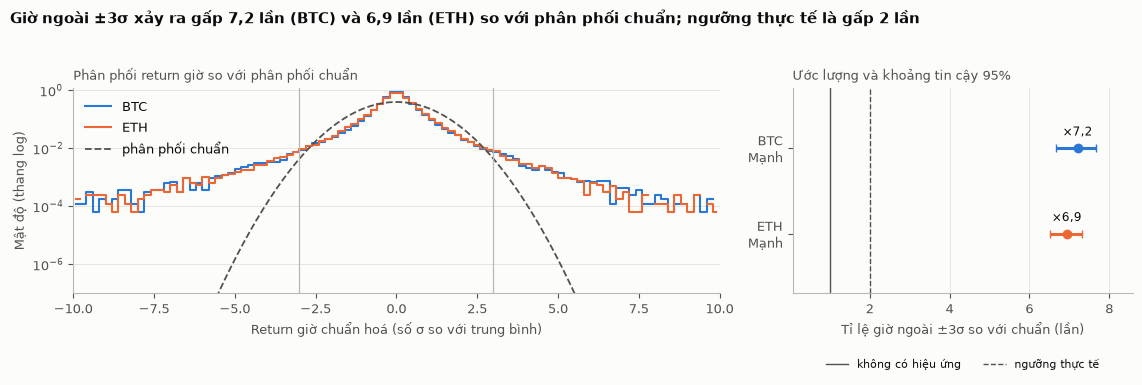

Giờ có |z| ≥ 10 không vẽ trên biểu đồ trái: BTC 41, ETH 35.
H1 BTC: ước lượng ×7,2, khoảng tin cậy 95% [×6,7; ×7,7], p Holm ≤ 0,013, mức bằng chứng: Mạnh
H1 ETH: ước lượng ×6,9, khoảng tin cậy 95% [×6,5; ×7,3], p Holm ≤ 0,013, mức bằng chứng: Mạnh


In [6]:
fig, a, b = newfig()
far = {}
for s in SYMS:
    x = ret_h[s].dropna().to_numpy(); z = (x - x.mean()) / x.std()
    far[s] = int((np.abs(z) >= 10).sum()); z = z[np.abs(z) < 10]
    cnt, ed = np.histogram(z, bins=np.linspace(-10, 10, 101), density=True)
    a.step((ed[:-1] + ed[1:]) / 2, np.where(cnt > 0, cnt, np.nan), where="mid", color=COL[s], lw=1.5, label=NAME[s])
g_ = np.linspace(-10, 10, 400)
a.plot(g_, stats.norm.pdf(g_), color=INK2, lw=1.3, ls="--", label="phân phối chuẩn")
for v in (-3, 3): a.axvline(v, color=GREY, lw=0.9)
a.set_yscale("log"); a.set_ylim(1e-7, 1.2); a.set_xlim(-10, 10)
a.set_xlabel("Return giờ chuẩn hoá (số σ so với trung bình)"); a.set_ylabel("Mật độ (thang log)")
a.set_title("Phân phối return giờ so với phân phối chuẩn", loc="left", fontsize=9.5, color=INK2); a.legend(loc="upper left")
eff_panel(b, "H1", "Tỉ lệ giờ ngoài ±3σ so với chuẩn (lần)")
finish(fig, "H1", f"Giờ ngoài ±3σ xảy ra gấp {vn(TH('H1', B_), 1)} lần (BTC) và {vn(TH('H1', E_), 1)} lần (ETH) so với phân phối chuẩn; ngưỡng thực tế là gấp 2 lần")
print(f"Giờ có |z| ≥ 10 không vẽ trên biểu đồ trái: BTC {far[B_]}, ETH {far[E_]}.")
say("H1")

### H2. Return giờ tự tương quan ở lag 1

Biểu đồ trái là hệ số tự tương quan (ACF) của return giờ ở 24 độ trễ đầu. Dải xám là ±0,10, ngưỡng thực tế đã khai báo: các điểm nằm trong dải nghĩa là return giờ trước gần như không báo trước return giờ sau. Biểu đồ phải là ACF lag 1 kèm khoảng tin cậy.

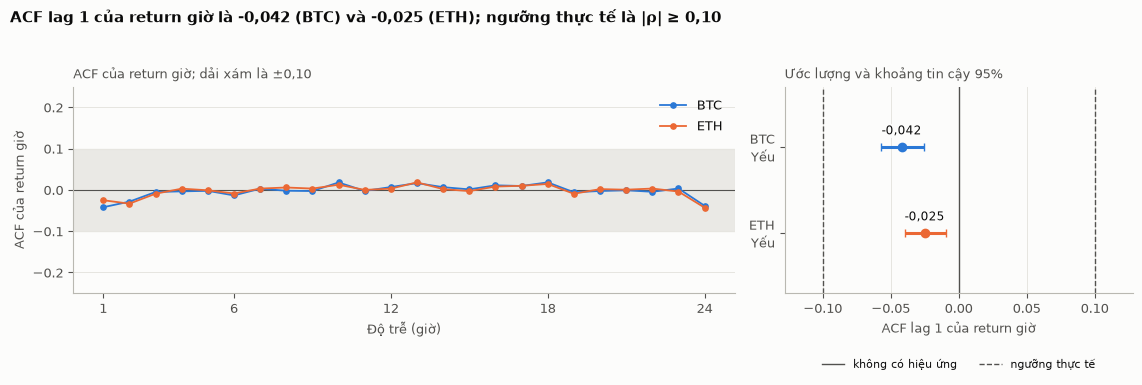

H2 BTC: ước lượng -0,042, khoảng tin cậy 95% [-0,057; -0,026], p Holm ≤ 0,013, mức bằng chứng: Yếu: có ý nghĩa nhưng nhỏ
H2 ETH: ước lượng -0,025, khoảng tin cậy 95% [-0,039; -0,009], p Holm 0,040, mức bằng chứng: Yếu: có ý nghĩa nhưng nhỏ


In [7]:
fig, a, b = newfig()
K_ = np.arange(1, 25)
a.axhspan(-0.10, 0.10, color=GRID, alpha=0.8, zorder=0)
a.axhline(0, color=INK2, lw=0.8)
for s in SYMS: a.plot(K_, acf_r.loc[K_, s], marker="o", ms=3.8, color=COL[s], lw=1.3, label=NAME[s])
a.set_ylim(-0.25, 0.25); a.set_xticks([1, 6, 12, 18, 24])
a.set_xlabel("Độ trễ (giờ)"); a.set_ylabel("ACF của return giờ")
a.set_title("ACF của return giờ; dải xám là ±0,10", loc="left", fontsize=9.5, color=INK2); a.legend(loc="upper right")
eff_panel(b, "H2", "ACF lag 1 của return giờ")
finish(fig, "H2", f"ACF lag 1 của return giờ là {vn(TH('H2', B_), 3)} (BTC) và {vn(TH('H2', E_), 3)} (ETH); ngưỡng thực tế là |ρ| ≥ 0,10")
say("H2")

### H3. Biến động gom cụm

Biểu đồ trái là ACF của độ lớn return (|return|) từ 1 đến 168 giờ (một tuần). Nếu giờ biến động mạnh thường kéo theo các giờ biến động mạnh sau đó, ACF dương và giảm chậm; các vạch dọc đánh dấu mỗi 24 giờ để thấy nhịp theo ngày. Đường nét đứt là ngưỡng thực tế 0,10.

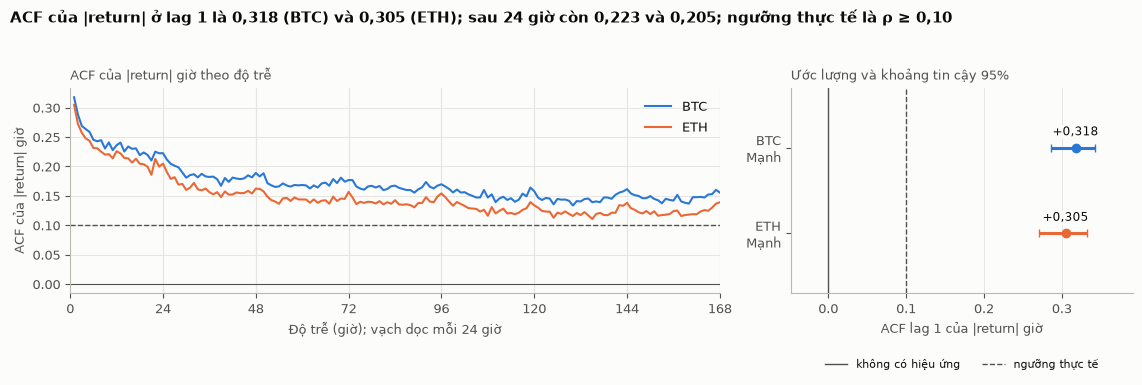

H3 BTC: ước lượng +0,318, khoảng tin cậy 95% [+0,286; +0,343], p Holm ≤ 0,013, mức bằng chứng: Mạnh
H3 ETH: ước lượng +0,305, khoảng tin cậy 95% [+0,271; +0,332], p Holm ≤ 0,013, mức bằng chứng: Mạnh


In [8]:
fig, a, b = newfig()
for s in SYMS: a.plot(acf_a.index, acf_a[s], color=COL[s], lw=1.5, label=NAME[s])
a.axhline(0.10, color=INK2, lw=1, ls="--"); a.axhline(0, color=INK2, lw=0.8)
for k in range(24, 169, 24): a.axvline(k, color=GRID, lw=0.9, zorder=0)
a.set_xticks(range(0, 169, 24)); a.set_xlim(0, 168)
a.set_xlabel("Độ trễ (giờ); vạch dọc mỗi 24 giờ"); a.set_ylabel("ACF của |return| giờ")
a.set_title("ACF của |return| giờ theo độ trễ", loc="left", fontsize=9.5, color=INK2); a.legend(loc="upper right")
eff_panel(b, "H3", "ACF lag 1 của |return| giờ")
finish(fig, "H3", f"ACF của |return| ở lag 1 là {vn(TH('H3', B_), 3)} (BTC) và {vn(TH('H3', E_), 3)} (ETH); sau 24 giờ còn {vn(acf_a.loc[24, B_], 3)} và {vn(acf_a.loc[24, E_], 3)}; ngưỡng thực tế là ρ ≥ 0,10")
say("H3")

### H4. Biến động ngày từ 2022 thấp hơn trước 2022

Biểu đồ trái là biến động năm hoá trượt 30 ngày của hai mã. Vạch đứng là 01/01/2022, các đoạn nét đứt là trung vị của biến động trượt trước và từ mốc đó, vùng xám là giai đoạn thị trường mỏng trước 2018. Kiểm định dùng tỉ số độ lệch chuẩn return ngày giữa hai giai đoạn, không dùng trung vị trượt, nên hai con số có thể lệch nhẹ nhau nhưng cùng hướng.

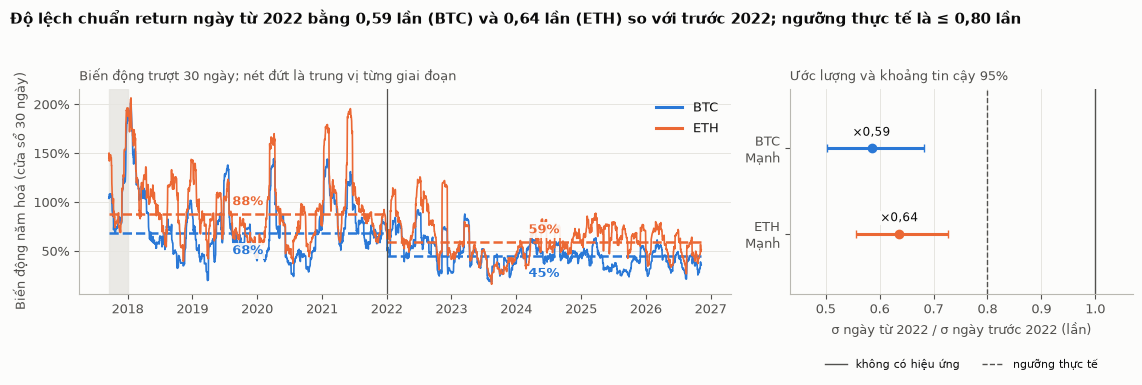

H4 BTC: ước lượng ×0,59, khoảng tin cậy 95% [×0,50; ×0,68], p Holm ≤ 0,0040, mức bằng chứng: Mạnh
H4 ETH: ước lượng ×0,64, khoảng tin cậy 95% [×0,56; ×0,73], p Holm ≤ 0,0040, mức bằng chứng: Mạnh


In [9]:
fig, a, b = newfig()
for s in SYMS:
    g = DD[DD["symbol"] == s].set_index("day")["ret"]
    v = (g.rolling(30).std() * np.sqrt(365) * 100).dropna()
    a.plot(v.index, v, color=COL[s], lw=1.2)
    lo_, hi_ = v[v.index < SPLIT_N].median(), v[v.index >= SPLIT_N].median()
    a.hlines(lo_, v.index[0], SPLIT_N, color=COL[s], ls="--", lw=1.8); a.hlines(hi_, SPLIT_N, v.index[-1], color=COL[s], ls="--", lw=1.8)
    a.annotate(f"{vn(lo_, 0)}%", (v.index[0] + (SPLIT_N - v.index[0]) / 2, lo_), textcoords="offset points", xytext=(0, 6 if s == E_ else -15), ha="center", color=COL[s], fontsize=9, fontweight="bold", bbox=dict(fc=BG, ec="none", pad=1.2, alpha=0.9))
    a.annotate(f"{vn(hi_, 0)}%", (SPLIT_N + (v.index[-1] - SPLIT_N) / 2, hi_), textcoords="offset points", xytext=(0, 6 if s == E_ else -15), ha="center", color=COL[s], fontsize=9, fontweight="bold", bbox=dict(fc=BG, ec="none", pad=1.2, alpha=0.9))
a.axvline(SPLIT_N, color=INK2, lw=0.9); a.axvspan(v.index[0], THIN_N, color=GRID, alpha=0.8, zorder=0)
a.yaxis.set_major_formatter(pctf); a.set_ylabel("Biến động năm hoá (cửa sổ 30 ngày)")
a.set_title("Biến động trượt 30 ngày; nét đứt là trung vị từng giai đoạn", loc="left", fontsize=9.5, color=INK2); sym_leg(a, loc="upper right")
eff_panel(b, "H4", "σ ngày từ 2022 / σ ngày trước 2022 (lần)")
finish(fig, "H4", f"Độ lệch chuẩn return ngày từ 2022 bằng {vn(TH('H4', B_), 2)} lần (BTC) và {vn(TH('H4', E_), 2)} lần (ETH) so với trước 2022; ngưỡng thực tế là ≤ 0,80 lần")
say("H4")

### H5. Biên độ biến động khác nhau giữa 24 giờ trong ngày

Biểu đồ trái là |return| trung bình của từng giờ trong ngày (giờ Việt Nam) chia cho mức trung bình chung của mã đó; đường nằm trên 1 là giờ biến động mạnh hơn bình thường. Biểu đồ phải là tỉ số giữa giờ mạnh nhất và giờ yếu nhất; kiểm định Friedman coi mỗi ngày là một khối nên không bị ảnh hưởng bởi tự tương quan giữa các giờ liền kề.

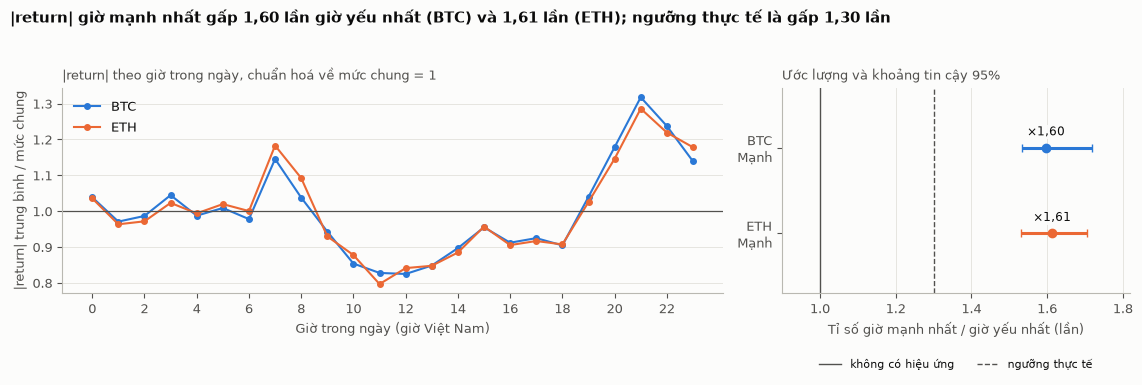

BTC: giờ mạnh nhất 21h (1,32 lần mức chung), giờ yếu nhất 12h (0,82 lần)
ETH: giờ mạnh nhất 21h (1,29 lần mức chung), giờ yếu nhất 11h (0,80 lần)
H5 BTC: ước lượng ×1,60, khoảng tin cậy 95% [×1,53; ×1,72], p Holm < 0,001, mức bằng chứng: Mạnh
H5 ETH: ước lượng ×1,61, khoảng tin cậy 95% [×1,53; ×1,71], p Holm < 0,001, mức bằng chứng: Mạnh


In [10]:
fig, a, b = newfig()
prof = h.groupby(["symbol", "hour"])["ar"].mean().unstack(0)[SYMS]; prof = prof / prof.mean()
for s in SYMS: a.plot(prof.index, prof[s], marker="o", ms=4, color=COL[s], lw=1.5, label=NAME[s])
a.axhline(1, color=INK2, lw=0.9)
a.set_xticks(range(0, 24, 2)); a.set_xlabel("Giờ trong ngày (giờ Việt Nam)"); a.set_ylabel("|return| trung bình / mức chung")
a.set_title("|return| theo giờ trong ngày, chuẩn hoá về mức chung = 1", loc="left", fontsize=9.5, color=INK2); a.legend(loc="upper left")
eff_panel(b, "H5", "Tỉ số giờ mạnh nhất / giờ yếu nhất (lần)")
finish(fig, "H5", f"|return| giờ mạnh nhất gấp {vn(TH('H5', B_), 2)} lần giờ yếu nhất (BTC) và {vn(TH('H5', E_), 2)} lần (ETH); ngưỡng thực tế là gấp 1,30 lần")
for s in SYMS: print(f"{NAME[s]}: giờ mạnh nhất {int(prof[s].idxmax())}h ({vn(prof[s].max(), 2)} lần mức chung), giờ yếu nhất {int(prof[s].idxmin())}h ({vn(prof[s].min(), 2)} lần)")
say("H5")

### H6. Cuối tuần biến động thấp hơn ngày thường

Biểu đồ trái là trung vị của |return| ngày theo từng thứ trong tuần; vùng xám là thứ Bảy và Chủ Nhật. Nếu cuối tuần yên hơn, hai cột cuối thấp hơn các cột còn lại. Biểu đồ phải là tỉ số trung vị cuối tuần chia cho trung vị ngày thường.

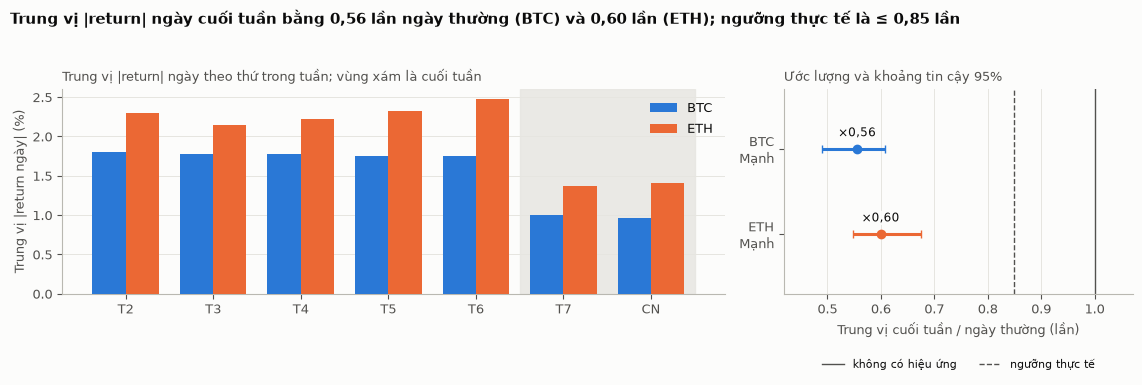

H6 BTC: ước lượng ×0,56, khoảng tin cậy 95% [×0,49; ×0,61], p Holm ≤ 0,0040, mức bằng chứng: Mạnh
H6 ETH: ước lượng ×0,60, khoảng tin cậy 95% [×0,55; ×0,67], p Holm ≤ 0,0040, mức bằng chứng: Mạnh


In [11]:
fig, a, b = newfig()
wk = DD.groupby(["symbol", DD["day"].dt.dayofweek])["ar"].median().unstack(0)[SYMS] * 100
w_ = 0.38; x_ = np.arange(7)
a.axvspan(4.5, 6.5, color=GRID, alpha=0.8, zorder=0)
for k, s in enumerate(SYMS): a.bar(x_ + (k - 0.5) * w_, wk[s], w_, color=COL[s], label=NAME[s], zorder=3)
a.set_xticks(x_); a.set_xticklabels(DOW); a.set_ylabel("Trung vị |return ngày| (%)")
a.set_title("Trung vị |return| ngày theo thứ trong tuần; vùng xám là cuối tuần", loc="left", fontsize=9.5, color=INK2); a.legend(loc="upper right")
eff_panel(b, "H6", "Trung vị cuối tuần / ngày thường (lần)")
finish(fig, "H6", f"Trung vị |return| ngày cuối tuần bằng {vn(TH('H6', B_), 2)} lần ngày thường (BTC) và {vn(TH('H6', E_), 2)} lần (ETH); ngưỡng thực tế là ≤ 0,85 lần")
say("H6")

### H7. Return log trung bình mỗi ngày khác 0

Biểu đồ trái là return log trung bình mỗi ngày trên cửa sổ trượt 365 ngày, tính bằng điểm cơ bản (1 bp = 0,01%). Vùng xám là ±5 bp, ngưỡng thực tế (khoảng 20% mỗi năm). Nếu đường trượt đổi dấu và vượt ra khỏi vùng xám theo cả hai phía, xu hướng trung bình phụ thuộc rất nhiều vào giai đoạn chọn mẫu. Biểu đồ phải là trung bình toàn lịch sử kèm khoảng tin cậy Newey–West.

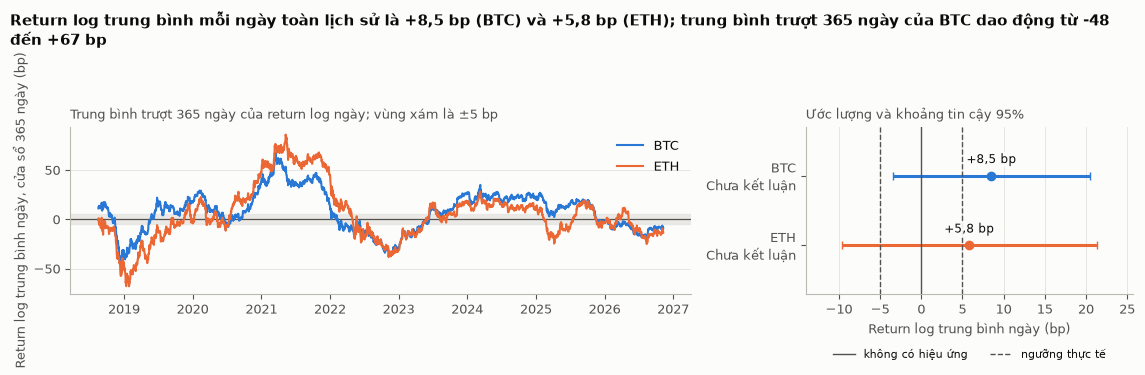

H7 BTC: ước lượng +8,5 bp, khoảng tin cậy 95% [-3,4 bp; +20,5 bp], p Holm 0,325, mức bằng chứng: Chưa kết luận
H7 ETH: ước lượng +5,8 bp, khoảng tin cậy 95% [-9,7 bp; +21,3 bp], p Holm 0,461, mức bằng chứng: Chưa kết luận


In [12]:
fig, a, b = newfig()
rng_ = {}
a.axhspan(-5, 5, color=GRID, alpha=0.8, zorder=0); a.axhline(0, color=INK2, lw=0.9)
for s in SYMS:
    g = DD[DD["symbol"] == s].set_index("day")["ret"] * 1e4
    m = g.rolling(365).mean().dropna(); rng_[s] = (m.min(), m.max())
    a.plot(m.index, m, color=COL[s], lw=1.5, label=NAME[s])
a.set_ylabel("Return log trung bình ngày, cửa sổ 365 ngày (bp)")
a.set_title("Trung bình trượt 365 ngày của return log ngày; vùng xám là ±5 bp", loc="left", fontsize=9.5, color=INK2); a.legend(loc="upper right")
eff_panel(b, "H7", "Return log trung bình ngày (bp)")
finish(fig, "H7", f"Return log trung bình mỗi ngày toàn lịch sử là {vn(TH('H7', B_), 1, sign=True)} bp (BTC) và {vn(TH('H7', E_), 1, sign=True)} bp (ETH); trung bình trượt 365 ngày của BTC dao động từ {vn(rng_[B_][0], 0, sign=True)} đến {vn(rng_[B_][1], 0, sign=True)} bp")
say("H7")

### H8. BTC và ETH đồng pha mạnh

Biểu đồ trái là mỗi chấm một ngày, trục ngang là return ngày của BTC và trục dọc là của ETH; đường màu là đường hồi quy. Các chấm càng bó sát đường chéo thì hai mã càng đồng pha. Biểu đồ phải là hệ số tương quan Pearson kèm khoảng tin cậy, so với ngưỡng 0,70.

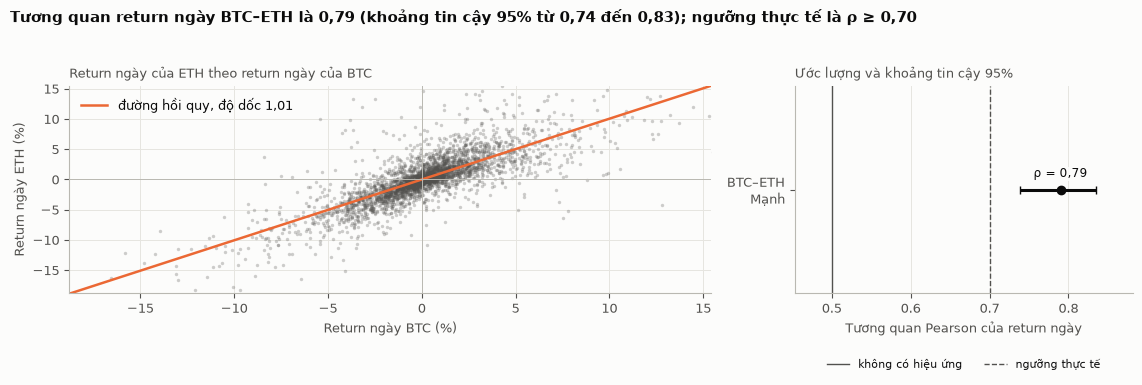

Số ngày vẽ: 3370; một số ngày cực đoan nằm ngoài khung nhìn của biểu đồ trái.
H8 BTC–ETH: ước lượng ρ = 0,79, khoảng tin cậy 95% [0,74; 0,83], p Holm ≤ 0,0040, mức bằng chứng: Mạnh


In [13]:
fig, a, b = newfig()
x_, y_ = dr[B_] * 100, dr[E_] * 100
a.scatter(x_, y_, s=6, alpha=0.28, color=INK2, lw=0)
k_, c0_ = np.polyfit(x_, y_, 1)
lim_ = np.percentile(np.r_[x_, y_], [0.3, 99.7]); lim_ = (lim_[0] - 1, lim_[1] + 1)
xx_ = np.array(lim_); a.plot(xx_, k_ * xx_ + c0_, color=COL[E_], lw=1.8, label=f"đường hồi quy, độ dốc {vn(k_, 2)}")
a.axhline(0, color=GREY, lw=0.7); a.axvline(0, color=GREY, lw=0.7)
a.set_xlim(lim_); a.set_ylim(lim_); a.grid(axis="x")
a.set_xlabel("Return ngày BTC (%)"); a.set_ylabel("Return ngày ETH (%)")
a.set_title("Return ngày của ETH theo return ngày của BTC", loc="left", fontsize=9.5, color=INK2); a.legend(loc="upper left")
eff_panel(b, "H8", "Tương quan Pearson của return ngày")
r8 = RR("H8")
finish(fig, "H8", f"Tương quan return ngày BTC–ETH là {vn(r8['theta'], 2)} (khoảng tin cậy 95% từ {vn(r8['ci'][0], 2)} đến {vn(r8['ci'][1], 2)}); ngưỡng thực tế là ρ ≥ 0,70")
print(f"Số ngày vẽ: {len(x_)}; một số ngày cực đoan nằm ngoài khung nhìn của biểu đồ trái.")
say("H8")

### H9. Tương quan BTC–ETH năm 2017 thấp hơn các năm sau

Biểu đồ trái là tương quan trượt 60 ngày giữa return ngày của BTC và ETH. Hai đoạn nét đứt là tương quan của cả năm 2017 và của giai đoạn từ 2018; vạch đứng là 01/01/2018. Biểu đồ phải là chênh lệch hai giá trị đó so với ngưỡng 0,10. Năm 2017 chỉ có hơn một trăm ngày nên khoảng tin cậy rộng hơn các phép thử khác.

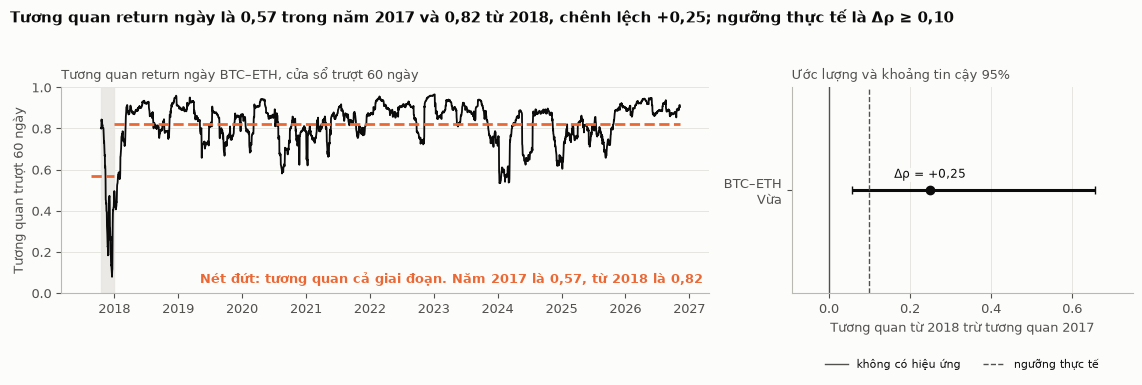

Số ngày của năm 2017 trong mẫu: 135.
H9 BTC–ETH: ước lượng Δρ = +0,25, khoảng tin cậy 95% [+0,06; +0,66], p Holm 0,036, mức bằng chứng: Vừa: chưa kiểm tra ổn định


In [14]:
fig, a, b = newfig()
rc_ = dr[B_].rolling(60).corr(dr[E_]).dropna()
a.axvspan(rc_.index[0], THIN_N, color=GRID, alpha=0.8, zorder=0)
a.plot(rc_.index, rc_, color=INK, lw=1.3)
m17, m18 = dr[dr.index < THIN_N], dr[dr.index >= THIN_N]
c17, c18 = s_cor(m17[B_], m17[E_]), s_cor(m18[B_], m18[E_])
a.hlines(c17, dr.index[0], THIN_N, color=COL[E_], ls="--", lw=2); a.hlines(c18, THIN_N, dr.index[-1], color=COL[E_], ls="--", lw=2)
a.text(0.99, 0.05, f"Nét đứt: tương quan cả giai đoạn. Năm 2017 là {vn(c17, 2)}, từ 2018 là {vn(c18, 2)}", transform=a.transAxes, ha="right", color=COL[E_], fontsize=9, fontweight="bold")
a.set_ylim(min(rc_.min(), c17) - 0.08, 1.0); a.set_ylabel("Tương quan trượt 60 ngày")
a.set_title("Tương quan return ngày BTC–ETH, cửa sổ trượt 60 ngày", loc="left", fontsize=9.5, color=INK2)
eff_panel(b, "H9", "Tương quan từ 2018 trừ tương quan 2017")
r9 = RR("H9")
finish(fig, "H9", f"Tương quan return ngày là {vn(c17, 2)} trong năm 2017 và {vn(c18, 2)} từ 2018, chênh lệch {vn(r9['theta'], 2, sign=True)}; ngưỡng thực tế là Δρ ≥ 0,10")
print(f"Số ngày của năm 2017 trong mẫu: {len(m17)}.")
say("H9")

### H10. Khối lượng tương đối đi cùng độ lớn return ngày

Các ngày được chia thành 10 nhóm theo khối lượng tương đối (khối lượng ngày chia trung vị 30 ngày trước đó); nhóm 10 là các ngày giao dịch sôi động nhất. Biểu đồ trái là |return| ngày trung bình của từng nhóm: đường dốc lên nghĩa là ngày giao dịch sôi động thường là ngày giá chạy mạnh. Biểu đồ phải là hệ số Spearman, so với ngưỡng 0,30.

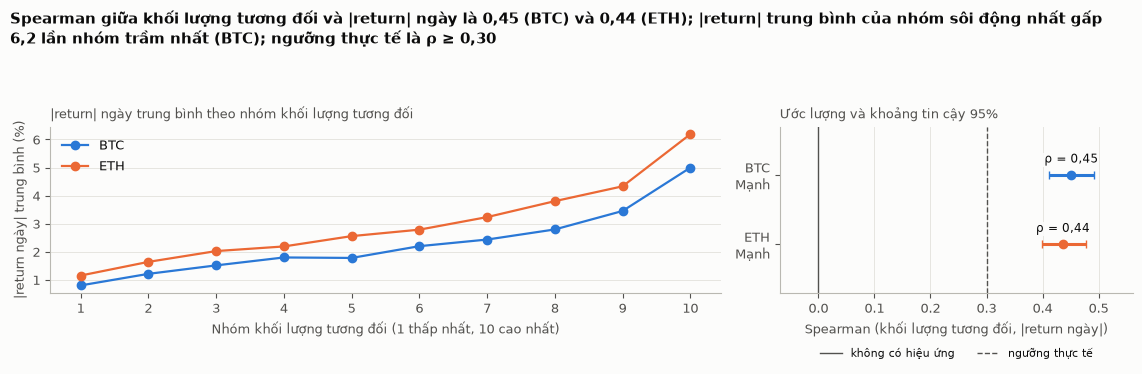

H10 BTC: ước lượng ρ = 0,45, khoảng tin cậy 95% [0,41; 0,49], p Holm ≤ 0,0040, mức bằng chứng: Mạnh
H10 ETH: ước lượng ρ = 0,44, khoảng tin cậy 95% [0,40; 0,48], p Holm ≤ 0,0040, mức bằng chứng: Mạnh


In [15]:
fig, a, b = newfig()
ratio10 = {}
for s in SYMS:
    g = DV[DV["symbol"] == s].copy(); g["bin"] = pd.qcut(g["rel_vol"], 10, labels=False)
    m = g.groupby("bin")["abs_ret"].mean() * 100; ratio10[s] = m.iloc[-1] / m.iloc[0]
    a.plot(m.index + 1, m, marker="o", color=COL[s], lw=1.6, label=NAME[s])
a.set_xticks(range(1, 11)); a.set_xlabel("Nhóm khối lượng tương đối (1 thấp nhất, 10 cao nhất)"); a.set_ylabel("|return ngày| trung bình (%)")
a.set_title("|return| ngày trung bình theo nhóm khối lượng tương đối", loc="left", fontsize=9.5, color=INK2); a.legend(loc="upper left")
eff_panel(b, "H10", "Spearman (khối lượng tương đối, |return ngày|)")
finish(fig, "H10", f"Spearman giữa khối lượng tương đối và |return| ngày là {vn(TH('H10', B_), 2)} (BTC) và {vn(TH('H10', E_), 2)} (ETH); |return| trung bình của nhóm sôi động nhất gấp {vn(ratio10[B_], 1)} lần nhóm trầm nhất (BTC); ngưỡng thực tế là ρ ≥ 0,30")
say("H10")

### H11. Tỉ lệ mua chủ động dự báo return giờ kế tiếp

Các giờ được chia thành 10 nhóm theo tỉ lệ mua chủ động (phần khối lượng do bên mua đặt lệnh thị trường); nhóm 10 là giờ bên mua áp đảo nhất. Biểu đồ trái là return trung bình của giờ kế tiếp theo từng nhóm, kèm thanh sai số thông thường (hẹp hơn thực tế vì return giờ có tự tương quan ở độ lớn). Nếu tỉ lệ mua chủ động dự báo được giá, đường phải dốc lên từ nhóm 1 đến nhóm 10; đường phẳng quanh 0 nghĩa là không.

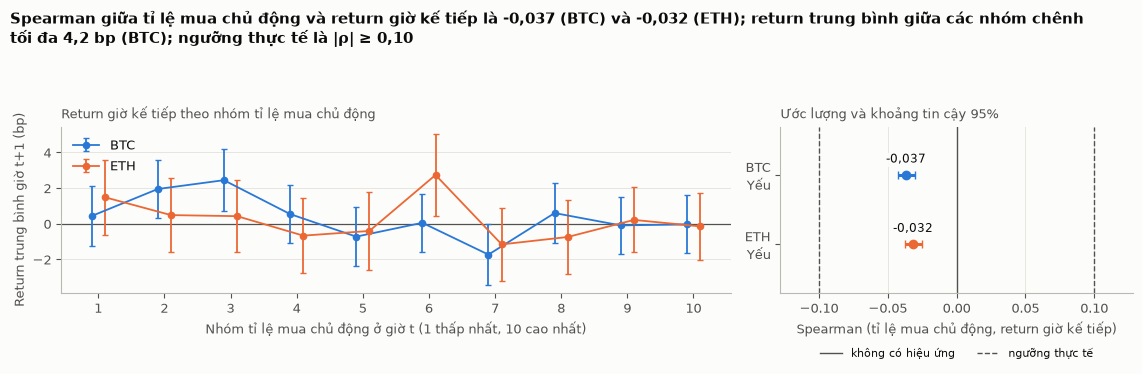

H11 BTC: ước lượng -0,037, khoảng tin cậy 95% [-0,043; -0,030], p Holm ≤ 0,013, mức bằng chứng: Yếu: có ý nghĩa nhưng nhỏ
H11 ETH: ước lượng -0,032, khoảng tin cậy 95% [-0,038; -0,025], p Holm ≤ 0,013, mức bằng chứng: Yếu: có ý nghĩa nhưng nhỏ


In [16]:
fig, a, b = newfig()
sp11 = {}
a.axhline(0, color=INK2, lw=0.9)
for k, s in enumerate(SYMS):
    g = FL[FL["symbol"] == s].copy(); g["bin"] = pd.qcut(g["tbr"], 10, labels=False)
    m = g.groupby("bin")["next_ret"].agg(["mean", "sem"]) * 1e4; sp11[s] = m["mean"].max() - m["mean"].min()
    a.errorbar(m.index + 1 + (k - 0.5) * 0.2, m["mean"], yerr=1.96 * m["sem"], fmt="o-", ms=4.5, color=COL[s], lw=1.3, capsize=2, label=NAME[s])
a.set_xticks(range(1, 11)); a.set_xlabel("Nhóm tỉ lệ mua chủ động ở giờ t (1 thấp nhất, 10 cao nhất)"); a.set_ylabel("Return trung bình giờ t+1 (bp)")
a.set_title("Return giờ kế tiếp theo nhóm tỉ lệ mua chủ động", loc="left", fontsize=9.5, color=INK2); a.legend(loc="upper left")
eff_panel(b, "H11", "Spearman (tỉ lệ mua chủ động, return giờ kế tiếp)")
finish(fig, "H11", f"Spearman giữa tỉ lệ mua chủ động và return giờ kế tiếp là {vn(TH('H11', B_), 3)} (BTC) và {vn(TH('H11', E_), 3)} (ETH); return trung bình giữa các nhóm chênh tối đa {vn(sp11[B_], 1)} bp (BTC); ngưỡng thực tế là |ρ| ≥ 0,10")
say("H11")

### H12. Có giờ nào có return trung bình khác 0

Biểu đồ trái là return trung bình của từng giờ trong ngày (giờ Việt Nam) kèm khoảng tin cậy 95% thông thường; vùng xám là ±10 bp, mức xấp xỉ phí giao dịch một chiều. Một giờ chỉ đáng chú ý nếu thanh tin cậy tách khỏi 0 và chấm nằm ngoài vùng xám. Biểu đồ phải là giờ lệch nhất của mỗi mã sau khi hiệu chỉnh cho 24 giờ.

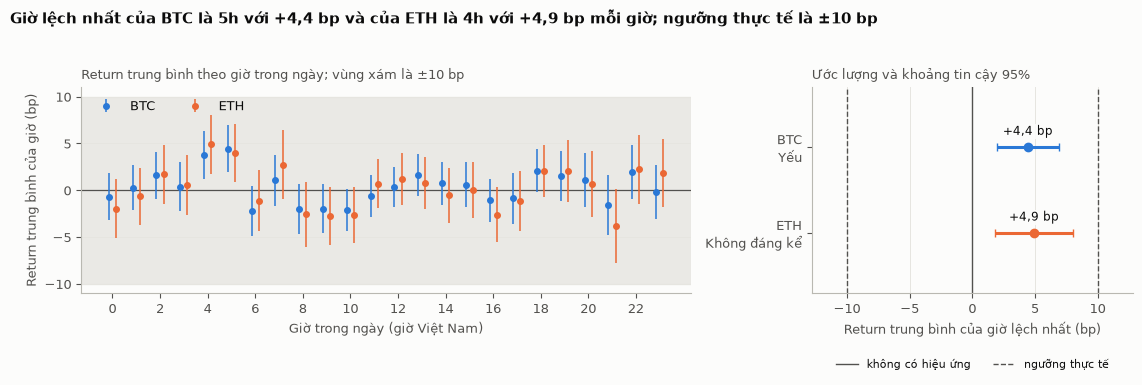

H12 BTC: ước lượng +4,4 bp, khoảng tin cậy 95% [+1,9 bp; +6,9 bp], p Holm 0,049, mức bằng chứng: Yếu: có ý nghĩa nhưng nhỏ
H12 ETH: ước lượng +4,9 bp, khoảng tin cậy 95% [+1,8 bp; +8,1 bp], p Holm 0,156, mức bằng chứng: Không đáng kể


In [17]:
fig, a, b = newfig()
a.axhspan(-10, 10, color=GRID, alpha=0.8, zorder=0); a.axhline(0, color=INK2, lw=0.9)
top = {}
for k, s in enumerate(SYMS):
    r_ = res[res["s"] == s]; top[s] = int(r_["mean_bp"].abs().idxmax())
    a.errorbar(r_.index + (k - 0.5) * 0.3, r_["mean_bp"], yerr=r_["ci_bp"], fmt="o", ms=4, color=COL[s], ecolor=COL[s], elinewidth=1.1, capsize=0, label=NAME[s])
a.set_xticks(range(0, 24, 2)); a.set_xlabel("Giờ trong ngày (giờ Việt Nam)"); a.set_ylabel("Return trung bình của giờ (bp)")
a.set_title("Return trung bình theo giờ trong ngày; vùng xám là ±10 bp", loc="left", fontsize=9.5, color=INK2); a.legend(loc="upper left", ncol=2)
eff_panel(b, "H12", "Return trung bình của giờ lệch nhất (bp)")
finish(fig, "H12", f"Giờ lệch nhất của BTC là {top[B_]}h với {vn(TH('H12', B_), 1, sign=True)} bp và của ETH là {top[E_]}h với {vn(TH('H12', E_), 1, sign=True)} bp mỗi giờ; ngưỡng thực tế là ±10 bp")
say("H12")

## 5. Tổng hợp bằng chứng và kiểm tra độ nhạy

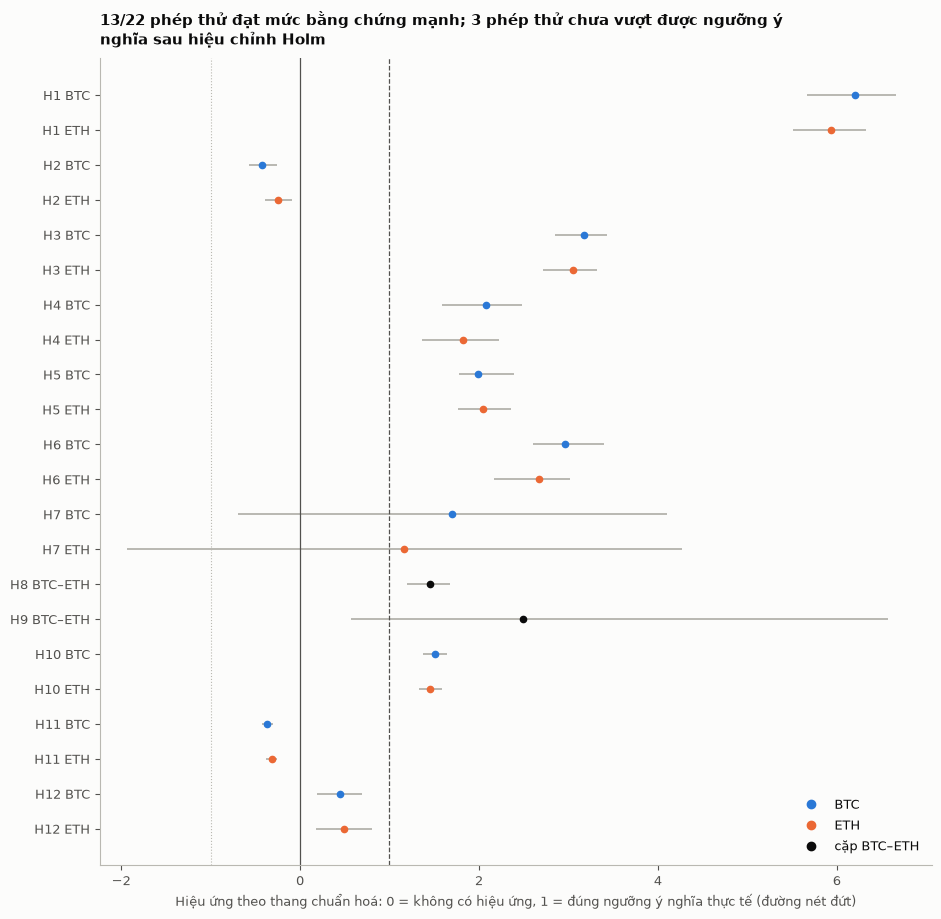

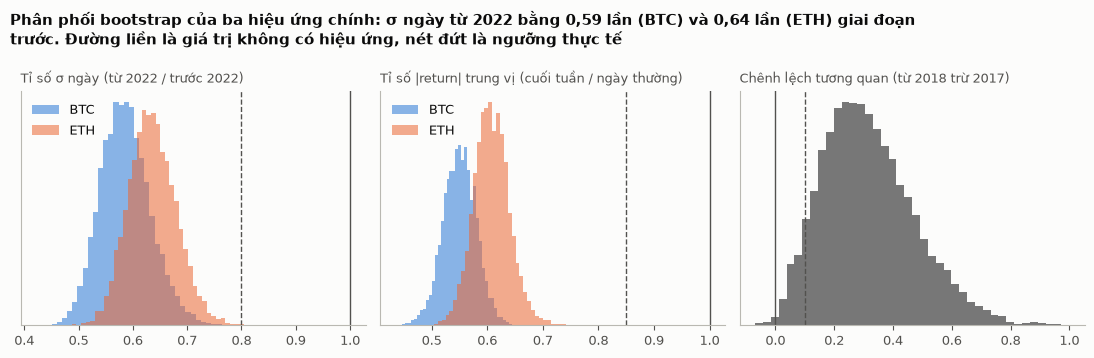

H1: tỉ lệ đuôi so với chuẩn, KTC 95% H3: ACF |return| lag 1, KTC 95%
Mã  Độ dài khối (giờ)                                                                     
BTC 24                                          [6,8; 7,6]                  [0,284; 0,325]
    168                                         [6,6; 7,7]                  [0,284; 0,343]
    720                                         [6,6; 7,7]                  [0,274; 0,352]
ETH 24                                          [6,5; 7,3]                  [0,270; 0,317]
    168                                         [6,5; 7,3]                  [0,273; 0,335]
    720                                         [6,4; 7,4]                  [0,260; 0,336]

Khối càng dài, khoảng tin cậy càng rộng vì giữ được nhiều phụ thuộc hơn. Nếu kết luận không đổi ở cả ba độ dài khối thì không phụ thuộc vào lựa chọn này.
Nếu nâng ngưỡng thực tế lên gấp rưỡi, 11/13 phát hiện mạnh vẫn vượt ngưỡng. Rớt ngưỡng: H8 BTC–ETH, H10 ETH.
Phép thử sát ngưỡng 0,05 (p Holm từ 0,02 đến 0,10), kết luận có thể đổi nếu thêm hoặc bớt vài chục ngày dữ liệu: H2 ETH (p Holm 0,040); H9 BTC–ETH (p Holm 0,036); H12 BTC (p Holm 0,049).
Mạnh: H1 BTC, H1 ETH, H3 BTC, H3 ETH, H4 BTC, H4 ETH, H5 BTC, H5 ETH, H6 BTC, H6 ETH, H8 BTC–ETH, H10 BTC, H10 ETH
Vừa: H9 BTC–ETH
Yếu: H2 BTC, H2 ETH, H11 BTC, H11 ETH, H12 BTC
Chưa kết luận: H7 BTC, H7 ETH
Không đáng kể: H12 ETH


In [18]:
m_ = len(REC)
G = {}
for r in REC:
    G.setdefault(r["grade"].split(":")[0], []).append(f"{r['sp']['id']} {r['lab']}")
k_strong, k_none = len(G.get("Mạnh", [])), len(G.get("Không đáng kể", [])) + len(G.get("Chưa kết luận", []))

fig, ax = plt.subplots(figsize=(9.5, 0.34 * m_ + 1.8))
for i, r in enumerate(REC):
    y = m_ - 1 - i
    ax.errorbar(r["x"], y, xerr=[[max(r["x"] - r["xl"], 0)], [max(r["xh"] - r["x"], 0)]], fmt="o", ms=4.5, color=COL.get(r["s"], INK),
                ecolor=GREY, elinewidth=1.4, capsize=0)
ax.axvline(0, color=INK2, lw=0.9); ax.axvline(1, color=INK2, lw=0.9, ls="--"); ax.axvline(-1, color=GREY, lw=0.8, ls=":")
ax.set_yticks(range(m_)); ax.set_yticklabels([f"{r['sp']['id']} {r['lab']}" for r in REC][::-1]); ax.grid(axis="y", visible=False)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], marker="o", ls="none", color=COL[s_], label=NAME[s_]) for s_ in SYMS] + [Line2D([0], [0], marker="o", ls="none", color=INK, label="cặp BTC–ETH")], loc="lower right")
ax.set_xlim(min(-1.6, min(r["xl"] for r in REC) - 0.3), max(r["xh"] for r in REC) + 0.4)
ax.set_xlabel("Hiệu ứng theo thang chuẩn hoá: 0 = không có hiệu ứng, 1 = đúng ngưỡng ý nghĩa thực tế (đường nét đứt)")
ttl(ax, f"{k_strong}/{m_} phép thử đạt mức bằng chứng mạnh; {k_none} phép thử chưa vượt được ngưỡng ý nghĩa sau hiệu chỉnh Holm")
save(fig, "kd1_bang_chung_forest")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
pick = [("H4", SYMS, "Tỉ số σ ngày (từ 2022 / trước 2022)"), ("H6", SYMS, "Tỉ số |return| trung vị (cuối tuần / ngày thường)"), ("H9", [None], "Chênh lệch tương quan (từ 2018 trừ 2017)")]
for ax, (hid, ss, tt) in zip(axes, pick):
    for r in [q for q in REC if q["sp"]["id"] == hid]:
        ax.hist(r["ts"], bins=40, color=COL.get(r["s"], INK), alpha=0.55, label=r["lab"])
    sp = [q for q in SPEC if q["id"] == hid][0]
    ax.axvline(sp["null"], color=INK2, lw=1); ax.axvline(sp["thr"], color=INK2, lw=1, ls="--")
    ax.set_title(tt, loc="left", fontsize=9.5, color=INK2); ax.set_yticks([]); ax.grid(False)
    if hid != "H9": ax.legend(loc="upper left")
b4 = {r["lab"]: r for r in REC if r["sp"]["id"] == "H4"}
fig.suptitle(textwrap.fill(f"Phân phối bootstrap của ba hiệu ứng chính: σ ngày từ 2022 bằng {vn(b4['BTC']['theta'], 2)} lần (BTC) và {vn(b4['ETH']['theta'], 2)} lần (ETH) giai đoạn trước. "
                           "Đường liền là giá trị không có hiệu ứng, nét đứt là ngưỡng thực tế", 105), x=0.01, ha="left", fontsize=10.5, fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "kd2_bootstrap_hieu_ung_chinh.png", dpi=150, facecolor=BG, bbox_inches="tight"); plt.show()

# độ nhạy theo độ dài khối
sens = []
for s in SYMS:
    x = get_ret(s, "full")[0]
    for L in (24, 168, 720):
        t1, t3 = boot(s_tail, [x], L, 300), boot(s_ac1a, [x], L, 300)
        sens.append({"Mã": NAME[s], "Độ dài khối (giờ)": L, "H1: tỉ lệ đuôi so với chuẩn, KTC 95%": f"[{vn(ci95(t1)[0], 1)}; {vn(ci95(t1)[1], 1)}]",
                     "H3: ACF |return| lag 1, KTC 95%": f"[{vn(ci95(t3)[0], 3)}; {vn(ci95(t3)[1], 3)}]"})
display(pd.DataFrame(sens).set_index(["Mã", "Độ dài khối (giờ)"]))
print("Khối càng dài, khoảng tin cậy càng rộng vì giữ được nhiều phụ thuộc hơn. Nếu kết luận không đổi ở cả ba độ dài khối thì không phụ thuộc vào lựa chọn này.")

# độ nhạy theo ngưỡng thực tế
robust = [f"{r['sp']['id']} {r['lab']}" for r in REC if r["grade"] == "Mạnh" and (r["x"] >= 1.5 if r["sp"]["mode"] == "dir" else abs(r["x"]) >= 1.5)]
lost = [f"{r['sp']['id']} {r['lab']}" for r in REC if r["grade"] == "Mạnh" and f"{r['sp']['id']} {r['lab']}" not in robust]
print(f"Nếu nâng ngưỡng thực tế lên gấp rưỡi, {len(robust)}/{k_strong} phát hiện mạnh vẫn vượt ngưỡng." + (f" Rớt ngưỡng: {', '.join(lost)}." if lost else ""))
edge = [f"{r['sp']['id']} {r['lab']} (p Holm {vn(r['adj'], 3)})" for r in REC if 0.02 <= r["adj"] <= 0.10 and not r["floor"]]
if edge: print("Phép thử sát ngưỡng 0,05 (p Holm từ 0,02 đến 0,10), kết luận có thể đổi nếu thêm hoặc bớt vài chục ngày dữ liệu: " + "; ".join(edge) + ".")
for g_ in ["Mạnh", "Vừa", "Yếu", "Ngược chiều", "Chưa kết luận", "Không đáng kể"]:
    if g_ in G: print(f"{g_}: {', '.join(G[g_])}")

Cách đọc kết quả:

- Mỗi phép thử chỉ trả lời đúng câu hỏi đã khai báo. «Mạnh» là mức bằng chứng cho một hiệu ứng thống kê có độ lớn đáng kể và ổn định, chưa phải bằng chứng nhân quả: kiểm định không cho biết vì sao hiệu ứng xảy ra.
- «Không đáng kể» và «Chưa kết luận» khác nhau. Nhóm đầu là bằng chứng cho hiệu ứng nhỏ, nhóm sau là chưa đủ dữ liệu để biết.
- Toàn bộ kiểm định chỉ dựa trên một quỹ đạo lịch sử duy nhất của hai tài sản, qua vài chu kỳ lớn. Block bootstrap xử lý được tự tương quan trong khối nhưng không thể tạo thêm chu kỳ mới, nên khoảng tin cậy của các hiệu ứng phụ thuộc chế độ thị trường vẫn có thể hẹp hơn thực tế.
- Các giả thuyết được chọn sau khi đã xem số mô tả (ví dụ H9 đến từ việc thấy tương quan 2017 thấp hơn). Hiệu chỉnh Holm chỉ tính các phép thử có mặt trong bảng, không tính những hướng đã xem rồi bỏ qua ở bước mô tả, nên p-value vẫn hơi lạc quan.
- Hiệu chỉnh Holm áp dụng cho họ phép thử đã khai báo ở phần 2. Các so sánh phát sinh về sau từ biểu đồ hay bảng ở notebook EDA thuộc dạng khám phá và không nằm trong họ này.

## 6. Kết luận về bằng chứng

In [19]:
from IPython.display import Markdown, display as _d
R = lambda i, s=None: next(r for r in REC if r["sp"]["id"] == i and r["s"] == s)
B_, E_ = "BTCUSDT", "ETHUSDT"
est = lambda r: r["sp"]["fmt"](r["theta"])
def ci(r):
    f = r["sp"].get("fc", r["sp"]["fmt"]); return f"khoảng tin cậy 95% từ {f(r['ci'][0])} đến {f(r['ci'][1])}"
gr = lambda r: r["grade"].split(":")[0].lower()
def one(r): return f"{est(r)} ({ci(r)}; mức bằng chứng: {gr(r)})"
def both(i): return f"BTC {one(R(i, B_))}; ETH {one(R(i, E_))}"
ph = lambda r: vn(r["adj"], 3)

txt = f'''
Kết quả của {len(REC)} phép thử, hiệu chỉnh Holm chung. Số liệu trong phần này được sinh từ kết quả ở trên nên đổi theo dữ liệu mới.

1. **Rủi ro đuôi dày và biến động gom cụm.** Tỉ lệ giờ ngoài ±3σ so với mức của phân phối chuẩn (H1): {both("H1")}. ACF lag 1 của |return| (H3): {both("H3")}. Return tự tương quan lag 1 (H2): {both("H2")}.

2. **Mùa vụ.** Tỉ số |return| trung bình giữa giờ mạnh nhất và giờ yếu nhất (H5): {both("H5")}. Trung vị |return| ngày cuối tuần so với ngày thường (H6): {both("H6")}. Về chiều lợi suất, giờ lệch nhất (H12) cho {both("H12")}; p Holm lần lượt {ph(R("H12", B_))} và {ph(R("H12", E_))}.

3. **BTC và ETH.** Tương quan return ngày (H8): {one(R("H8"))}. Chênh lệch tương quan giữa giai đoạn từ 2018 và năm 2017 (H9): {one(R("H9"))}, p Holm {ph(R("H9"))}.

4. **Biến động và lợi suất theo thời gian.** Tỉ số độ lệch chuẩn return ngày từ 2022 so với trước 2022 (H4): {both("H4")}. Return log trung bình mỗi ngày (H7): {both("H7")}; p Holm lần lượt {ph(R("H7", B_))} và {ph(R("H7", E_))}.

5. **Khối lượng và dòng lệnh chủ động mua.** Spearman giữa khối lượng tương đối và |return| ngày (H10): {both("H10")}. Spearman giữa tỉ lệ mua chủ động và return giờ kế tiếp (H11): {both("H11")}.
'''
_d(Markdown(txt))

weak = [f"{r['sp']['id']} {r['lab']}" for r in REC if r["grade"].startswith(("Chưa kết luận", "Không đáng kể", "Yếu", "Ngược chiều"))]
edge = [f"{r['sp']['id']} {r['lab']} (p Holm {vn(r['adj'], 3)})" for r in REC if 0.02 <= r["adj"] <= 0.10 and not r["floor"]]
print("Phép thử chưa đạt mức bằng chứng vừa trở lên:", ", ".join(weak) if weak else "không có")
print("Phép thử sát ngưỡng 0,05:", "; ".join(edge) if edge else "không có")


Kết quả của 22 phép thử, hiệu chỉnh Holm chung. Số liệu trong phần này được sinh từ kết quả ở trên nên đổi theo dữ liệu mới.

1. **Rủi ro đuôi dày và biến động gom cụm.** Tỉ lệ giờ ngoài ±3σ so với mức của phân phối chuẩn (H1): BTC ×7,2 (khoảng tin cậy 95% từ ×6,7 đến ×7,7; mức bằng chứng: mạnh); ETH ×6,9 (khoảng tin cậy 95% từ ×6,5 đến ×7,3; mức bằng chứng: mạnh). ACF lag 1 của |return| (H3): BTC +0,318 (khoảng tin cậy 95% từ +0,286 đến +0,343; mức bằng chứng: mạnh); ETH +0,305 (khoảng tin cậy 95% từ +0,271 đến +0,332; mức bằng chứng: mạnh). Return tự tương quan lag 1 (H2): BTC -0,042 (khoảng tin cậy 95% từ -0,057 đến -0,026; mức bằng chứng: yếu); ETH -0,025 (khoảng tin cậy 95% từ -0,039 đến -0,009; mức bằng chứng: yếu).

2. **Mùa vụ.** Tỉ số |return| trung bình giữa giờ mạnh nhất và giờ yếu nhất (H5): BTC ×1,60 (khoảng tin cậy 95% từ ×1,53 đến ×1,72; mức bằng chứng: mạnh); ETH ×1,61 (khoảng tin cậy 95% từ ×1,53 đến ×1,71; mức bằng chứng: mạnh). Trung vị |return| ngày cuối tuần so với ngày thường (H6): BTC ×0,56 (khoảng tin cậy 95% từ ×0,49 đến ×0,61; mức bằng chứng: mạnh); ETH ×0,60 (khoảng tin cậy 95% từ ×0,55 đến ×0,67; mức bằng chứng: mạnh). Về chiều lợi suất, giờ lệch nhất (H12) cho BTC +4,4 bp (khoảng tin cậy 95% từ +1,9 bp đến +6,9 bp; mức bằng chứng: yếu); ETH +4,9 bp (khoảng tin cậy 95% từ +1,8 bp đến +8,1 bp; mức bằng chứng: không đáng kể); p Holm lần lượt 0,049 và 0,156.

3. **BTC và ETH.** Tương quan return ngày (H8): ρ = 0,79 (khoảng tin cậy 95% từ 0,74 đến 0,83; mức bằng chứng: mạnh). Chênh lệch tương quan giữa giai đoạn từ 2018 và năm 2017 (H9): Δρ = +0,25 (khoảng tin cậy 95% từ +0,06 đến +0,66; mức bằng chứng: vừa), p Holm 0,036.

4. **Biến động và lợi suất theo thời gian.** Tỉ số độ lệch chuẩn return ngày từ 2022 so với trước 2022 (H4): BTC ×0,59 (khoảng tin cậy 95% từ ×0,50 đến ×0,68; mức bằng chứng: mạnh); ETH ×0,64 (khoảng tin cậy 95% từ ×0,56 đến ×0,73; mức bằng chứng: mạnh). Return log trung bình mỗi ngày (H7): BTC +8,5 bp (khoảng tin cậy 95% từ -3,4 bp đến +20,5 bp; mức bằng chứng: chưa kết luận); ETH +5,8 bp (khoảng tin cậy 95% từ -9,7 bp đến +21,3 bp; mức bằng chứng: chưa kết luận); p Holm lần lượt 0,325 và 0,461.

5. **Khối lượng và dòng lệnh chủ động mua.** Spearman giữa khối lượng tương đối và |return| ngày (H10): BTC ρ = 0,45 (khoảng tin cậy 95% từ 0,41 đến 0,49; mức bằng chứng: mạnh); ETH ρ = 0,44 (khoảng tin cậy 95% từ 0,40 đến 0,48; mức bằng chứng: mạnh). Spearman giữa tỉ lệ mua chủ động và return giờ kế tiếp (H11): BTC -0,037 (khoảng tin cậy 95% từ -0,043 đến -0,030; mức bằng chứng: yếu); ETH -0,032 (khoảng tin cậy 95% từ -0,038 đến -0,025; mức bằng chứng: yếu).


Phép thử chưa đạt mức bằng chứng vừa trở lên: H2 BTC, H2 ETH, H7 BTC, H7 ETH, H11 BTC, H11 ETH, H12 BTC, H12 ETH
Phép thử sát ngưỡng 0,05: H2 ETH (p Holm 0,040); H9 BTC–ETH (p Holm 0,036); H12 BTC (p Holm 0,049)


### Giới hạn

- Chuỗi giờ có tự tương quan mạnh ở độ lớn. Block bootstrap, sai số chuẩn Newey–West và kiểm định Friedman xử lý được phần lớn, nhưng khoảng tin cậy vẫn có thể hẹp hơn thực tế khi độ dài khối chưa bao trùm hết phụ thuộc (xem bảng độ nhạy theo độ dài khối).
- Giả thuyết và ngưỡng thực tế được chọn sau khi đã xem số mô tả, nên đây là kiểm định xác nhận có điều kiện, không phải kiểm định tiền đăng ký.
- Dữ liệu chỉ là một quỹ đạo lịch sử của hai tài sản trên một sàn, qua vài chu kỳ lớn. Kiểm định không thể tạo thêm chu kỳ, nên các hiệu ứng phụ thuộc chế độ thị trường có độ bất định lớn hơn khoảng tin cậy thể hiện.
- Ngưỡng thực tế (ví dụ 10 điểm cơ bản cho phí giao dịch, hiệu ứng tối thiểu 0,10 cho tương quan) là lựa chọn của người phân tích. Bảng độ nhạy cho biết bao nhiêu kết luận mạnh còn đứng vững khi nâng ngưỡng.
- Kết quả là mô tả thống kê, không phải bằng chứng nhân quả.

### Hướng làm tiếp

1. Dùng dữ liệu tích luỹ sau ngày chạy này làm mẫu kiểm tra ngoài mẫu thật sự: giữ nguyên giả thuyết và ngưỡng, chạy lại khi có thêm vài tháng dữ liệu, rồi xem các kết luận mạnh có còn đúng không.
2. Kiểm định các hiệu ứng theo chế độ thị trường (tăng, giảm, đi ngang) để xem mùa vụ, tương quan BTC–ETH và quan hệ khối lượng–biến động có đổi theo chế độ không.
3. Dự báo biến động ngoài mẫu bằng mô hình HAR-RV hoặc GARCH có thêm biến giờ và cuối tuần, so với độ lệch chuẩn lăn.
4. Thêm các mã khác (SOL, BNB) và một sàn thứ hai để kiểm tra các hiệu ứng có phụ thuộc vào cặp BTC–ETH trên Binance hay không.

## 7. Xuất bảng kết quả cho Power BI

Ô dưới ghi `powerbi/fact_hyp.csv`, mỗi dòng là một phép thử cho một mã, để trang kiểm định của dashboard dùng đúng các kết quả ở trên.

In [20]:
os.makedirs(ROOT / "data", exist_ok=True)
GROUP = {"H1": "Rủi ro đuôi và gom cụm", "H2": "Rủi ro đuôi và gom cụm", "H3": "Rủi ro đuôi và gom cụm",
         "H5": "Mùa vụ", "H6": "Mùa vụ", "H12": "Mùa vụ",
         "H8": "BTC và ETH", "H9": "BTC và ETH",
         "H4": "Biến động theo thời gian", "H7": "Biến động theo thời gian",
         "H10": "Khối lượng và dòng lệnh", "H11": "Khối lượng và dòng lệnh"}
yn_ = lambda v: "Không áp dụng" if v is None else ("Đạt" if v else "Không đạt")
rows_ = []
for r in REC:
    sp = r["sp"]; f_ = sp.get("fc", sp["fmt"])
    rows_.append(dict(test_id=sp["id"], test_no=int(sp["id"][1:]), nhom=GROUP[sp["id"]], ten=sp["name"], ma=r["lab"],
                      uoc_luong=r["theta"], ktc_duoi=r["ci"][0], ktc_tren=r["ci"][1],
                      uoc_luong_text=sp["fmt"](r["theta"]), ktc_text=f"[{f_(r['ci'][0])}; {f_(r['ci'][1])}]",
                      nguong=sp["thr_txt"], p_tho=r["p"], p_holm=r["adj"],
                      hai_nua=yn_(r["sh"]), bo_2017=yn_(r["se"]),
                      muc=r["grade"].split(":")[0], muc_thu_tu={"Mạnh": 1, "Vừa": 2, "Yếu": 3, "Không đáng kể": 4, "Chưa kết luận": 5, "Ngược chiều": 6}[r["grade"].split(":")[0]]))
pd.DataFrame(rows_).to_csv(ROOT / "data" / "fact_hyp.csv", index=False, encoding="utf-8-sig")
print(f"Đã ghi data/fact_hyp.csv: {len(rows_)} dòng.")

Đã ghi powerbi/fact_hyp.csv: 22 dòng.
